# Healthcare Billing Anomaly Detection
## Step 1: Data Understanding and Exploratory Data Analysis (EDA)

**Author:** Healthcare Billing Anomaly Detection Assessment  
**Stage:** Step 1 of 4 (Step 1: EDA | Step 2: Data Cleaning | Step 3: Segmentation & Modeling | Step 4: Results & Interpretation)  
**Strict Scope Rule:** Exploratory Data Analysis ONLY. In accordance with clinical assessment protocols, **no rows are dropped, no values are imputed, and no data transformations are committed** in this notebook.

### Business Objective
Healthcare billing systems process millions of charge lines annually. Due to manual entry errors, complex fee schedules, system interface glitches, and fraudulent or unbundled billing practices, anomalous charges frequently leak through claim generation engines. 
The goal of this multi-step assessment is to build an **unsupervised machine learning anomaly detection engine** that identifies anomalous billing amounts within **meaningful clinical and operational segments** (e.g., procedure, provider, specialty).

### Step 1 EDA Goals
1. Establish comprehensive data understanding and baseline schema profiling.
2. Conduct an exhaustive audit of data quality (missingness, duplicates, polarity, categorical inconsistencies, and system artifacts).
3. Profile the target distribution (`ChargeAmount`) and quantify its statistical dispersion.
4. Evaluate categorical dimensions to identify which column creates the most distinct charge groups (to mathematically guide segmentation).
5. Analyze temporal trends and operational posting latency.
6. Explore multivariable relationships (e.g., charge vs. units).
7. Empirically prove why global anomaly detection fails and segment-wise anomaly detection is strictly necessary.
8. Synthesize key findings and define the roadmap for Step 2 (Data Cleaning).

## 1. Setup and Loading

In this section, we import the core scientific Python libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`), configure plotting defaults for publication-quality visual output, load the healthcare charge dataset and accompanying data dictionary, and inspect the initial dataset shape, schema, and sample records.

In [1]:
# Import standard data science and visualization libraries
import warnings
warnings.filterwarnings('ignore')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configure visualization settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Configure pandas display formats
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Ensure output directory for figures exists
os.makedirs('figures', exist_ok=True)
print("Environment configured successfully. Ready for analysis.")

Environment configured successfully. Ready for analysis.


In [2]:
# Load raw Excel data and data dictionary
excel_file = 'Charge Data.xlsx'

print(f"Loading '{excel_file}'...")
df = pd.read_excel(excel_file, sheet_name='Charge Data')
dict_df = pd.read_excel(excel_file, sheet_name='Data Dictionary')

print("\n" + "="*50)
print(f"Charge Data Loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Data Dictionary Loaded: {dict_df.shape[0]} documented fields")
print("="*50)

Loading 'Charge Data.xlsx'...

Charge Data Loaded: 314,221 rows x 16 columns
Data Dictionary Loaded: 15 documented fields


In [3]:
# Inspect column names, non-null counts, data types, and memory usage
print("=== CHARGE DATA SCHEMA & MEMORY USAGE ===")
df.info()

print("\n=== FIRST 5 ROWS OF CHARGE DATA ===")
df.head(5)

=== CHARGE DATA SCHEMA & MEMORY USAGE ===
<class 'pandas.DataFrame'>
RangeIndex: 314221 entries, 0 to 314220
Data columns (total 16 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   PatientAccountNumber       314221 non-null  str           
 1   PatientName                314221 non-null  str           
 2   PhysicianCode              314221 non-null  str           
 3   PhysicianName              314221 non-null  str           
 4   PlaceOfServiceCode         314221 non-null  str           
 5   PlaceOfServiceDescription  314221 non-null  str           
 6   ProcedureCode              314221 non-null  str           
 7   ProcedureCode.1            314221 non-null  object        
 8   ProcedureDescription       314221 non-null  str           
 9   ServiceLine                314221 non-null  str           
 10  PayerCompanyName           314221 non-null  str           
 11  DateOfService        

In [4]:
# Display and evaluate the Data Dictionary
print("=== OFFICIAL DATA DICTIONARY ===")
display_dict = dict_df.copy()
display_dict.columns = [c.strip() for c in display_dict.columns]
print(display_dict.to_string(index=False))

# Schema reconciliation: Identify undocumented columns or discrepancies
dict_columns = set(dict_df['Column Name'].str.strip())
df_columns = set(df.columns)

undocumented = df_columns - dict_columns
unmatched_dict = dict_columns - df_columns

print("\n=== SCHEMA AUDIT & DISCREPANCY CHECK ===")
print(f"Columns in dataset: {len(df_columns)}")
print(f"Columns documented in Data Dictionary: {len(dict_columns)}")
if undocumented:
    print(f"\nWARNING: Undocumented columns in dataset ({len(undocumented)}): {undocumented}")
    for col in sorted(undocumented):
        print(f"   -> Sample values for '{col}': {df[col].head(3).tolist()}")
if unmatched_dict:
    print(f"\nWARNING: Documented columns missing from dataset ({len(unmatched_dict)}): {unmatched_dict}")

=== OFFICIAL DATA DICTIONARY ===
              Column Name     Data Type                                                                                                                              Description
     PatientAccountNumber       VARCHAR             Unique identifier assigned to a patient's account in the billing system. A patient account may have multiple charge records.
              PatientName       VARCHAR                                                                                    Name of the patient who received the medical service.
            PhysicianCode       VARCHAR                                                                            Unique code assigned to the physician or healthcare provider.
            PhysicianName       VARCHAR                                                                               Name of the physician associated with the medical service.
       PlaceOfServiceCode       VARCHAR Standardized code identifying where the he

### Finding / So What (Section 1)
- **Scale and Granularity:** The dataset contains **314,221 historical healthcare billing charge records** across **16 columns**, spanning an outpatient clinical practice environment. It occupies ~75 MB in RAM, allowing efficient vectorized processing.
- **Undocumented Column Discrepancy (`ProcedureCode.1`):** The data dictionary defines 15 columns, but the transaction table has 16 columns. The extra column, `ProcedureCode.1`, contains industry-standard **5-digit AMA CPT codes** (e.g., `92550`, `99204`, `31231`), whereas `ProcedureCode` is an internal synthetic surrogate key (`PROC-0279`, `PROC-0117`). In Step 2, this column should be renamed (e.g., `CPTCode`) or reconciled to maintain clinical interpretability.
- **Baseline Data Types:** Dates (`DateOfService`, `PostingDate`) are successfully parsed as `datetime64[us]`. Amount columns (`ChargeAmount`, `TotalUnits`) are numeric `float64`. Most identifiers and descriptive attributes are text objects.

## 2. Data Quality Overview

A rigorous unsupervised anomaly detection model requires high data integrity. Anomalies detected by ML should reflect true billing anomalies, not unhandled data hygiene failures. In this section, we audit:
1. Missing values per column (count and percentage).
2. Exact duplicate rows.
3. Negative and zero values in transaction amount and unit fields.
4. Inconsistent categorical representations (case differences, padding, spelling).
5. Columns with inappropriate data types, zero-variance constants, or chronologically impossible date combinations.

=== MISSING VALUE & CARDINALITY AUDIT ===
                                Data Type  Missing Count  Missing Pct (%)  Unique Values
PatientAccountNumber                  str              0             0.00          38787
PatientName                           str              0             0.00          38787
PhysicianCode                         str              0             0.00             48
PhysicianName                         str              0             0.00             48
PlaceOfServiceCode                    str              0             0.00              1
PlaceOfServiceDescription             str              0             0.00              1
ProcedureCode                         str              0             0.00            310
ProcedureCode.1                    object              0             0.00            310
ProcedureDescription                  str              0             0.00            289
ServiceLine                           str              0            

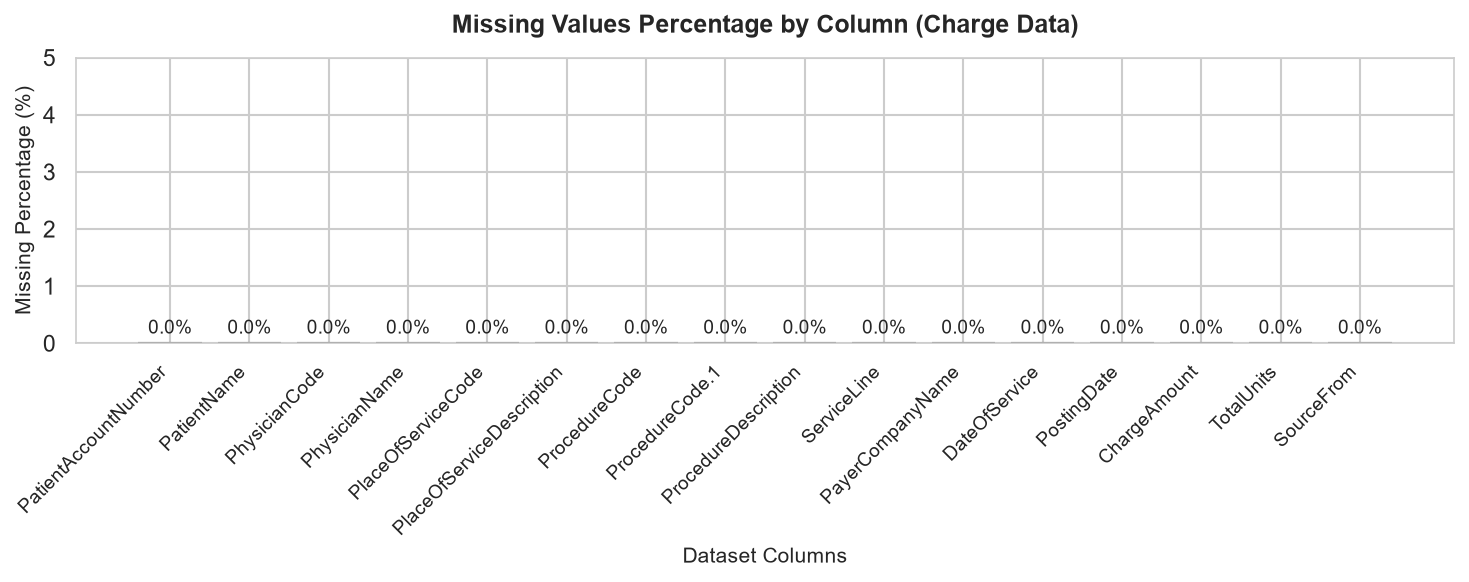

In [5]:
# 1. Missing values audit
missing_counts = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_report = pd.DataFrame({
    'Data Type': df.dtypes,
    'Missing Count': missing_counts,
    'Missing Pct (%)': missing_pct,
    'Unique Values': df.nunique()
})

print("=== MISSING VALUE & CARDINALITY AUDIT ===")
print(missing_report.to_string())

# Plot missing values (even if 0, confirms completeness visually)
plt.figure(figsize=(10, 4))
bars = plt.bar(missing_report.index, missing_report['Missing Pct (%)'], color='#2b5c8f', edgecolor='black', alpha=0.8)
plt.title('Missing Values Percentage by Column (Charge Data)', fontsize=12, fontweight='bold', pad=12)
plt.ylabel('Missing Percentage (%)', fontsize=10)
plt.xlabel('Dataset Columns', fontsize=10)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.ylim(0, 5)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.1, f'{yval:.1f}%', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('figures/01_missing_values.png', dpi=300, bbox_inches='tight')
plt.show()

In [6]:
# 2. Exact duplicate rows audit
exact_dups = df.duplicated().sum()
dup_pct = (exact_dups / len(df)) * 100

print(f"=== EXACT DUPLICATE ROWS AUDIT ===")
print(f"Total Exact Duplicate Rows: {exact_dups:,} ({dup_pct:.2f}% of all records)")

if exact_dups > 0:
    print("\nSample of exact duplicate records (sorted by patient & service date):")
    sample_dups = df[df.duplicated(keep=False)].sort_values(
        by=['PatientAccountNumber', 'DateOfService', 'ProcedureCode']
    ).head(6)
    print(sample_dups[['PatientAccountNumber', 'PatientName', 'PhysicianName', 'ProcedureDescription', 'DateOfService', 'ChargeAmount', 'TotalUnits']].to_string())

=== EXACT DUPLICATE ROWS AUDIT ===
Total Exact Duplicate Rows: 1,829 (0.58% of all records)

Sample of exact duplicate records (sorted by patient & service date):
     PatientAccountNumber PatientName PhysicianName       ProcedureDescription DateOfService  ChargeAmount  TotalUnits
1179           PAT-000020  Sara Lopez    Lance King  EXCISION/DESTRUC INTRANAS    2024-08-16      2,000.00        1.00
1180           PAT-000020  Sara Lopez    Lance King  EXCISION/DESTRUC INTRANAS    2024-08-16      2,000.00        1.00
1175           PAT-000020  Sara Lopez    Lance King  NASL/SINUS ENDO; W/BX POL    2024-08-22        495.00        1.00
1176           PAT-000020  Sara Lopez    Lance King  NASL/SINUS ENDO; W/BX POL    2024-08-22        495.00        1.00
1171           PAT-000020  Sara Lopez    Lance King  NASL/SINUS ENDO; W/BX POL    2024-09-05        495.00        1.00
1172           PAT-000020  Sara Lopez    Lance King  NASL/SINUS ENDO; W/BX POL    2024-09-05        495.00        1.00


In [7]:
# 3. Polarity audit: Zero, negative, and positive values
amount_cols = ['ChargeAmount', 'TotalUnits']
polarity_data = []

for col in amount_cols:
    neg_mask = df[col] < 0
    zero_mask = df[col] == 0
    pos_mask = df[col] > 0
    
    polarity_data.append({
        'Field': col,
        'Negative Count': neg_mask.sum(),
        'Negative Pct (%)': (neg_mask.sum() / len(df)) * 100,
        'Zero Count': zero_mask.sum(),
        'Zero Pct (%)': (zero_mask.sum() / len(df)) * 100,
        'Positive Count': pos_mask.sum(),
        'Positive Pct (%)': (pos_mask.sum() / len(df)) * 100,
        'Minimum': df[col].min(),
        'Maximum': df[col].max()
    })

polarity_df = pd.DataFrame(polarity_data)
print("=== AMOUNT & UNIT POLARITY AUDIT ===")
print(polarity_df.to_string(index=False))

# Deep dive into the 47,569 zero-dollar charge records
zero_charge_df = df[df['ChargeAmount'] == 0]
print("\nTop 10 Procedures associated with $0 ChargeAmount:")
zero_procs = zero_charge_df['ProcedureDescription'].value_counts().head(10)
zero_procs_pct = (zero_procs / len(zero_charge_df)) * 100
zero_summary = pd.DataFrame({'Zero Charge Count': zero_procs, 'Pct of Zero Charges (%)': zero_procs_pct})
print(zero_summary.to_string())

=== AMOUNT & UNIT POLARITY AUDIT ===
       Field  Negative Count  Negative Pct (%)  Zero Count  Zero Pct (%)  Positive Count  Positive Pct (%)  Minimum   Maximum
ChargeAmount               0              0.00       47569         15.14          266652             84.86     0.00 40,000.00
  TotalUnits               0              0.00        8791          2.80          305430             97.20     0.00    270.00

Top 10 Procedures associated with $0 ChargeAmount:
                                    Zero Charge Count  Pct of Zero Charges (%)
ProcedureDescription                                                          
POSTOPERATIVE F/U VISIT I                        9376                    19.71
Unmapped                                         8784                    18.47
HEARING AID FITTING/CHECKING                     6579                    13.83
NASAL ENDOSCOPY DX                               2799                     5.88
SUBLINGUAL DROP RAPID RAMP UP VIAL               2004      

In [8]:
# 4. Categorical consistency audit (casing, leading/trailing spaces, placeholder values)
cat_fields = [
    'PhysicianCode', 'PhysicianName', 'PlaceOfServiceCode', 'PlaceOfServiceDescription',
    'ProcedureCode', 'ProcedureDescription', 'ServiceLine', 'PayerCompanyName', 'SourceFrom'
]

cat_audit = []
for col in cat_fields:
    series_str = df[col].astype(str)
    raw_n = series_str.nunique()
    stripped_n = series_str.str.strip().nunique()
    upper_n = series_str.str.strip().str.upper().nunique()
    whitespace_issues = (series_str.str.strip() != series_str).sum()
    
    cat_audit.append({
        'Column': col,
        'Raw Unique': raw_n,
        'Stripped Unique': stripped_n,
        'Upper Unique': upper_n,
        'Case/Space Inconsistencies': raw_n - upper_n,
        'Whitespace Padding Rows': whitespace_issues
    })

cat_audit_df = pd.DataFrame(cat_audit)
print("=== CATEGORICAL CONSISTENCY AUDIT ===")
print(cat_audit_df.to_string(index=False))

# Inspect specific inconsistencies discovered
print("\n1. ServiceLine Breakdown (note case splitting & unmapped categories):")
print(df['ServiceLine'].value_counts(dropna=False).to_string())

print("\n2. PayerCompanyName Case Split Detail:")
mhealth_variants = df[df['PayerCompanyName'].str.upper() == 'MHEALTH']['PayerCompanyName'].value_counts()
print(mhealth_variants.to_string())

=== CATEGORICAL CONSISTENCY AUDIT ===
                   Column  Raw Unique  Stripped Unique  Upper Unique  Case/Space Inconsistencies  Whitespace Padding Rows
            PhysicianCode          48               48            48                           0                        0
            PhysicianName          48               48            48                           0                        0
       PlaceOfServiceCode           1                1             1                           0                        0
PlaceOfServiceDescription           1                1             1                           0                        0
            ProcedureCode         310              310           310                           0                        0
     ProcedureDescription         289              289           289                           0                        0
              ServiceLine           8                8             7                           1            

In [9]:
# 5. Domain validity, constant columns, and date logic audit
print("=== DOMAIN VALIDITY & CONSTANT COLUMNS ===")
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print(f"Constant Columns (Zero Variance across all 314,221 rows): {constant_cols}")
for c in constant_cols:
    print(f"   -> {c}: '{df[c].iloc[0]}'")

# Date chronology check: PostingDate must logically occur on or after DateOfService
posting_lag = (df['PostingDate'] - df['DateOfService']).dt.days
neg_lag_mask = posting_lag < 0

print("\n=== DATE LOGIC AUDIT: POSTING LAG ===")
print(f"DateOfService Range: {df['DateOfService'].min().date()} to {df['DateOfService'].max().date()}")
print(f"PostingDate Range:   {df['PostingDate'].min().date()} to {df['PostingDate'].max().date()}")
print(f"Negative Posting Lag Records (PostingDate < DateOfService): {neg_lag_mask.sum()} ({neg_lag_mask.sum()/len(df)*100:.4f}%)")

if neg_lag_mask.sum() > 0:
    print("\nSample anomalous negative lag records:")
    anom_dates = df[neg_lag_mask][['PatientAccountNumber', 'DateOfService', 'PostingDate', 'ServiceLine', 'ChargeAmount']]
    anom_dates['LagDays'] = posting_lag[neg_lag_mask]
    print(anom_dates.to_string())

=== DOMAIN VALIDITY & CONSTANT COLUMNS ===
Constant Columns (Zero Variance across all 314,221 rows): ['PlaceOfServiceCode', 'PlaceOfServiceDescription', 'SourceFrom']
   -> PlaceOfServiceCode: 'POS-001'
   -> PlaceOfServiceDescription: 'Aidas Medical Office'
   -> SourceFrom: 'Aidas'

=== DATE LOGIC AUDIT: POSTING LAG ===
DateOfService Range: 2023-01-03 to 2026-09-14
PostingDate Range:   2023-01-04 to 2026-09-15
Negative Posting Lag Records (PostingDate < DateOfService): 4 (0.0013%)

Sample anomalous negative lag records:
       PatientAccountNumber DateOfService PostingDate ServiceLine  ChargeAmount  LagDays
1843             PAT-000047    2025-05-19  2025-05-12     ALLERGY         37.00       -7
88085            PAT-008823    2023-01-18  2023-01-11     ALLERGY         36.50       -7
136384           PAT-012597    2024-03-25  2024-03-12    Unmapped          0.00      -13
155342           PAT-016605    2024-10-25  2024-10-21    Unmapped          0.00       -4


### Finding / So What (Section 2)
- **Zero Missingness vs. Implicit Missingness:** There are 0 standard `NaN`/null values in the dataset. However, categorical columns contain implicit missingness and placeholder categories, including **8,784 `'Unmapped'`** and **9 `'UNDEFINED'`** service line records, as well as generic payers like `'Miscellaneous'` (3,116) and `'Other'` (56).
- **Exact Duplicate Rows (1,829 rows, 0.58%):** There are 1,829 identical duplicate rows across all 16 fields. These represent system double-postings or re-submissions that must be deduplicated in Step 2 to avoid distorting density-based anomaly estimators.
- **High Prevalence of Zero-Dollar Charges (47,569 rows, 15.14%):** More than 15% of all billing lines have a `ChargeAmount` of $0.00. Clinical inspection reveals these are legitimate medical billing artifacts:
  - CPT `99024` (Postoperative follow-up visit included in global surgical package fee).
  - Unmapped or bundled service items.
  - In Step 2/3, zero-dollar charges must be segmented or separated from positive charge anomaly detection, as an anomaly detector trained on pooled zeros will suffer from inflated zero-mass distortion.
- **Categorical Inconsistencies:**
  - `ServiceLine` contains a case split: `'SURGERY'` (6,923 rows) vs. `'Surgery'` (1 row).
  - `PayerCompanyName` contains a case split: `'Mhealth'` (113 rows) vs. `'MHealth'` (1 row).
- **Zero-Variance Constant Columns:** `PlaceOfServiceCode` (`POS-001`), `PlaceOfServiceDescription` (`Aidas Medical Office`), and `SourceFrom` (`Aidas`) each have only 1 unique value across all 314,221 records. They provide zero predictive information and should be dropped during feature cleaning in Step 2.
- **Chronological Date Inversion:** Exactly 4 records have `PostingDate < DateOfService` (up to -13 days lag). In standard healthcare billing, a charge cannot be posted before the patient is seen. These 4 rows represent data corruption or system clock errors.

## 3. Target Variable Profiling (Charge Amount)

The primary target variable for billing anomaly detection is `ChargeAmount`. Understanding its distributional properties—central tendency, spread, skewness, kurtosis, and tail density—is critical for selecting the appropriate anomaly detection algorithms (e.g., Mahalanobis distance vs. tree-based isolation vs. non-parametric quantiles).

In [10]:
# Target variable summary statistics
charge = df['ChargeAmount']

mean_val = charge.mean()
median_val = charge.median()
std_val = charge.std()
min_val = charge.min()
max_val = charge.max()
q25_val = charge.quantile(0.25)
q75_val = charge.quantile(0.75)
iqr_val = q75_val - q25_val
skew_val = charge.skew()
kurt_val = charge.kurtosis()

stats_summary = pd.DataFrame({
    'Metric': [
        'Count', 'Mean ($)', 'Median ($)', 'Std Dev ($)', 'Min ($)', 
        '25th Percentile Q1 ($)', '75th Percentile Q3 ($)', 'IQR ($)', 
        'Max ($)', 'Skewness', 'Kurtosis', 'Mean / Median Ratio'
    ],
    'Value': [
        f"{len(charge):,}", f"{mean_val:,.2f}", f"{median_val:,.2f}", f"{std_val:,.2f}", f"{min_val:,.2f}",
        f"{q25_val:,.2f}", f"{q75_val:,.2f}", f"{iqr_val:,.2f}", 
        f"{max_val:,.2f}", f"{skew_val:.2f}", f"{kurt_val:.2f}", f"{mean_val / median_val:.2f}x"
    ]
})

print("=== TARGET VARIABLE STATISTICAL PROFILE ===")
print(stats_summary.to_string(index=False))

=== TARGET VARIABLE STATISTICAL PROFILE ===
                Metric     Value
                 Count   314,221
              Mean ($)    220.33
            Median ($)    120.00
           Std Dev ($)    654.03
               Min ($)      0.00
25th Percentile Q1 ($)     36.50
75th Percentile Q3 ($)    285.00
               IQR ($)    248.50
               Max ($) 40,000.00
              Skewness     20.08
              Kurtosis    637.94
   Mean / Median Ratio     1.84x


In [11]:
# Detailed percentile ladder
percentiles = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999, 1.00]
pct_values = charge.quantile(percentiles)
pct_df = pd.DataFrame({
    'Percentile': [f"{p*100:.1f}th" for p in percentiles],
    'Charge Amount ($)': [f"{val:,.2f}" for val in pct_values],
    'Multiplier over Median': [f"{val / median_val:.2f}x" if median_val > 0 else 'N/A' for val in pct_values]
})

print("=== CHARGE AMOUNT PERCENTILE LADDER ===")
print(pct_df.to_string(index=False))

=== CHARGE AMOUNT PERCENTILE LADDER ===
Percentile Charge Amount ($) Multiplier over Median
     1.0th              0.00                  0.00x
     5.0th              0.00                  0.00x
    10.0th              0.00                  0.00x
    25.0th             36.50                  0.30x
    50.0th            120.00                  1.00x
    75.0th            285.00                  2.38x
    90.0th            345.00                  2.88x
    95.0th            553.50                  4.61x
    99.0th          2,000.00                 16.67x
    99.9th          8,000.00                 66.67x
   100.0th         40,000.00                333.33x


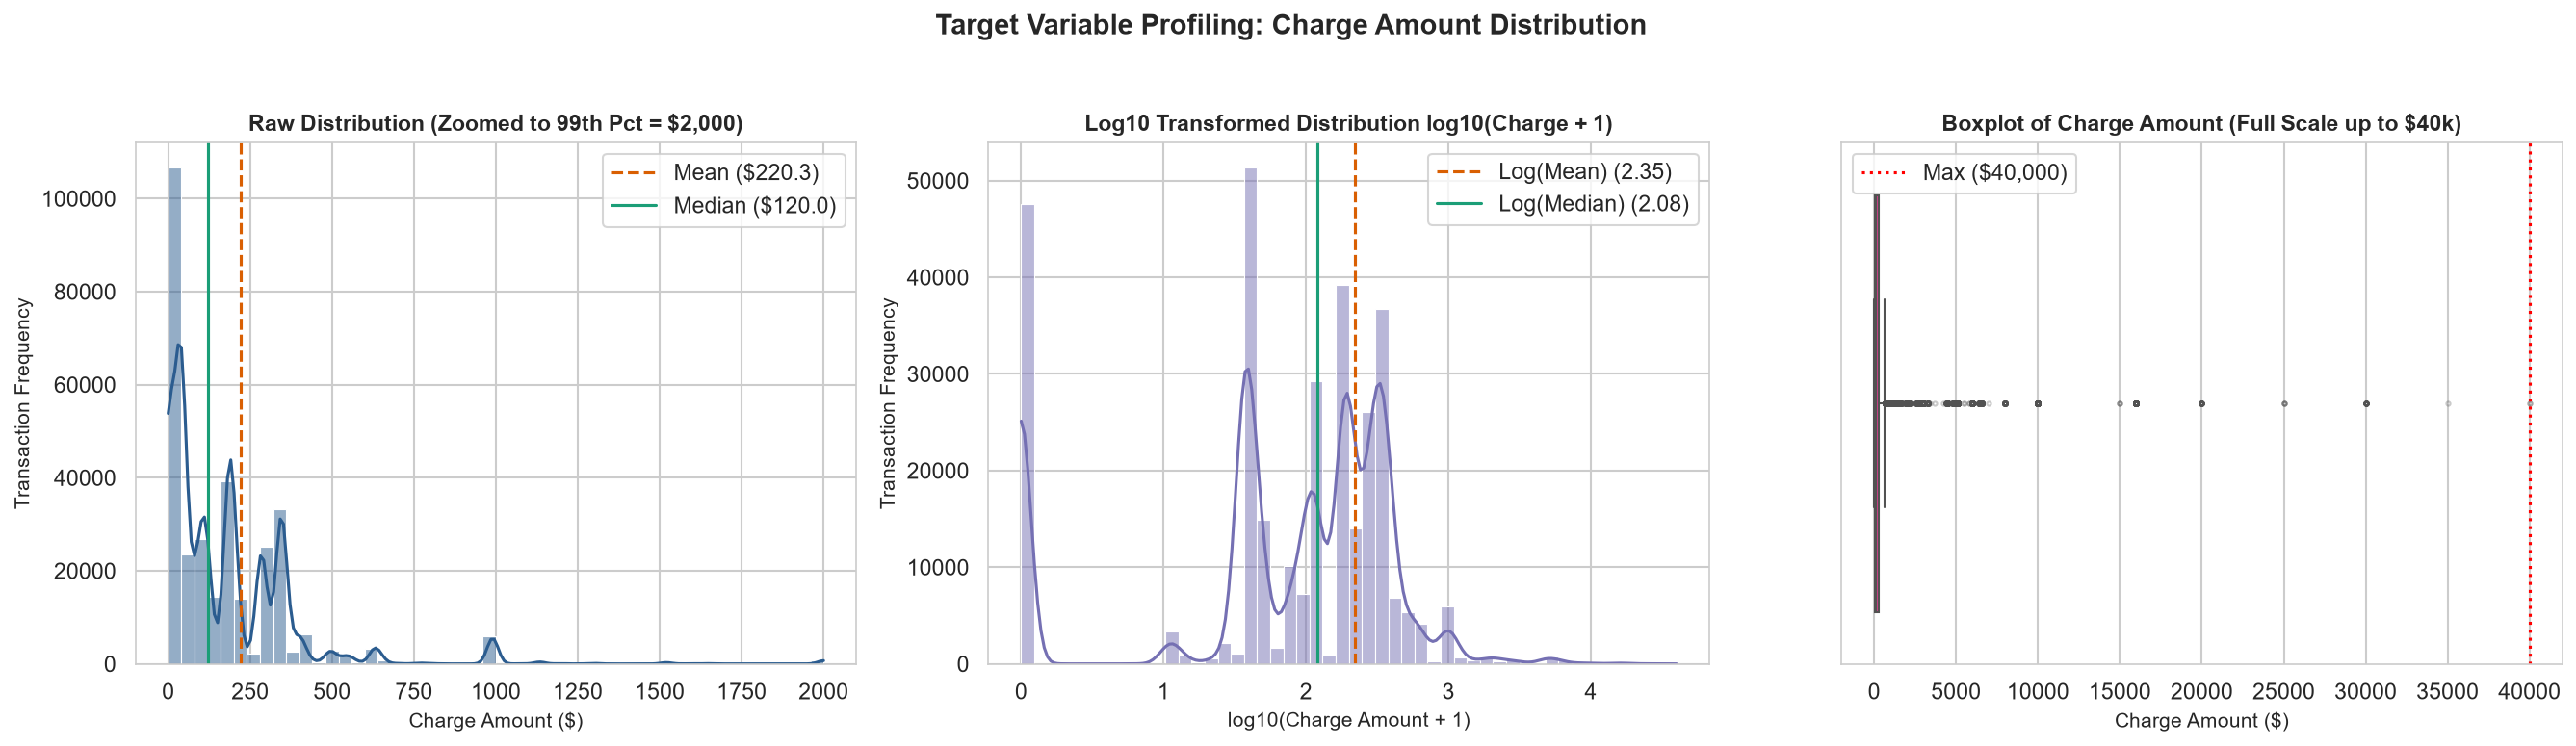

In [12]:
# Distribution Visualizations: Raw Histogram, Log-scale Histogram, and Boxplot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Raw Histogram (zoomed to 99th percentile for visual clarity)
p99 = charge.quantile(0.99)
sns.histplot(charge[charge <= p99], bins=50, kde=True, color='#2b5c8f', ax=axes[0])
axes[0].axvline(mean_val, color='#d95f02', linestyle='--', linewidth=1.5, label=f'Mean (${mean_val:.1f})')
axes[0].axvline(median_val, color='#1b9e77', linestyle='-', linewidth=1.5, label=f'Median (${median_val:.1f})')
axes[0].set_title(f'Raw Distribution (Zoomed to 99th Pct = ${p99:,.0f})', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Charge Amount ($)', fontsize=10)
axes[0].set_ylabel('Transaction Frequency', fontsize=10)
axes[0].legend(frameon=True)

# Plot 2: Log-scale Histogram log10(Charge + 1)
log_charge = np.log10(charge + 1)
sns.histplot(log_charge, bins=50, kde=True, color='#7570b3', ax=axes[1])
axes[1].axvline(np.log10(mean_val + 1), color='#d95f02', linestyle='--', linewidth=1.5, label=f'Log(Mean) ({np.log10(mean_val+1):.2f})')
axes[1].axvline(np.log10(median_val + 1), color='#1b9e77', linestyle='-', linewidth=1.5, label=f'Log(Median) ({np.log10(median_val+1):.2f})')
axes[1].set_title('Log10 Transformed Distribution log10(Charge + 1)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('log10(Charge Amount + 1)', fontsize=10)
axes[1].set_ylabel('Transaction Frequency', fontsize=10)
axes[1].legend(frameon=True)

# Plot 3: Boxplot showing full range and extreme tail
sns.boxplot(x=charge, color='#e7298a', ax=axes[2], flierprops={'marker': 'o', 'markersize': 2, 'alpha': 0.3})
axes[2].set_title('Boxplot of Charge Amount (Full Scale up to $40k)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Charge Amount ($)', fontsize=10)
axes[2].axvline(max_val, color='red', linestyle=':', label=f'Max (${max_val:,.0f})')
axes[2].legend(frameon=True)

plt.suptitle('Target Variable Profiling: Charge Amount Distribution', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('figures/02_target_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

### Finding / So What (Section 3)
- **Extreme Right Skewness & Leptokurtosis:** `ChargeAmount` exhibits extreme positive skewness (**20.08**) and massive kurtosis (**637.94**). The tail stretches all the way to **$40,000.00**, while 75% of charges are at or below **$285.00**.
- **Mean-to-Median Divergence:** The mean charge (**$220.33**) is **1.84 times the median ($120.00)**. This substantial gap is a classic symptom of extreme high-value outliers pulling the arithmetic average upward.
- **Multimodal Log-Distribution:** The $\log_{10}$ histogram reveals distinct multiple modes:
  1. A sharp spike at $\log_{10}(0+1) = 0$ corresponding to the 47,569 zero-dollar claims.
  2. A cluster around $\log_{10}(36.5 + 1) pprox 1.57$ representing standard allergy shots and audiology diagnostics.
  3. A cluster around $\log_{10}(185 + 1) pprox 2.27$ to $2.45$ representing established patient outpatient visits.
  4. A sparse, long tail reaching $\log_{10}(40,000 + 1) pprox 4.60$ representing major complex surgeries.
- **Modeling Implications:**
  - Standard Gaussian assumptions (e.g., $Z$-score $> 3$) will fail catastrophically because the underlying data is profoundly non-normal. Under a global $Z$-score, almost all surgical procedures would be falsely flagged as anomalies simply because they are expensive.
  - Tree-based isolation algorithms (Isolation Forest) and non-parametric quantile estimators, combined with log/power transformations, will be required in Step 3.

## 4. Categorical Analysis & Segmentation Drivers

In medical billing, what constitutes an "anomalous" charge cannot be evaluated in a vacuum. A $2,500 bill is routine for a complex endoscopic sinus surgery, but fraudulent or erroneous for an routine hearing test or allergy injection.
In this section, we:
1. Examine unique counts and top categories across all categorical columns.
2. Calculate charge statistics (median, mean, std, volume) grouped by service line, procedure, provider, and payer.
3. Visualize charge distributions across key clinical categories using boxplots.
4. **Identify which categorical column creates the most distinct charge groups** using ANOVA / Eta-squared ($\eta^2$, percentage of variance explained) to rigorously guide segmentation in Step 3.

In [13]:
# 1. Unique counts and dominant categories
cat_summary = []
for col in cat_fields:
    top_val = df[col].value_counts().index[0]
    top_cnt = df[col].value_counts().iloc[0]
    top_pct = (top_cnt / len(df)) * 100
    cat_summary.append({
        'Categorical Column': col,
        'Unique Count': df[col].nunique(),
        'Top Category': top_val,
        'Top Category Count': f"{top_cnt:,}",
        'Top Category Pct (%)': f"{top_pct:.1f}%"
    })

print("=== CATEGORICAL CARDINALITY & DOMINANCE SUMMARY ===")
print(pd.DataFrame(cat_summary).to_string(index=False))

=== CATEGORICAL CARDINALITY & DOMINANCE SUMMARY ===
       Categorical Column  Unique Count             Top Category Top Category Count Top Category Pct (%)
            PhysicianCode            48                 PHY-0030             61,966                19.7%
            PhysicianName            48             Joshua Moses             61,966                19.7%
       PlaceOfServiceCode             1                  POS-001            314,221               100.0%
PlaceOfServiceDescription             1     Aidas Medical Office            314,221               100.0%
            ProcedureCode           310                PROC-0292             51,246                16.3%
     ProcedureDescription           289 IMMUNOTHERAPY INJECTIONS             51,246                16.3%
              ServiceLine             8                   OFFICE            148,526                47.3%
         PayerCompanyName            27                     BCBS            108,446                34.5%
   

In [14]:
# 2. Charge Amount grouped by ServiceLine
sl_summary = df.groupby('ServiceLine')['ChargeAmount'].agg(
    Record_Count='count',
    Median_Charge='median',
    Mean_Charge='mean',
    Std_Dev='std',
    Min_Charge='min',
    Max_Charge='max',
    Total_Billed='sum'
).sort_values(by='Record_Count', ascending=False)

sl_summary['Volume_Pct (%)'] = (sl_summary['Record_Count'] / len(df)) * 100
sl_summary['Billed_Pct (%)'] = (sl_summary['Total_Billed'] / df['ChargeAmount'].sum()) * 100

print("=== CHARGE PROFILE BY SERVICE LINE ===")
print(sl_summary.to_string())

=== CHARGE PROFILE BY SERVICE LINE ===
             Record_Count  Median_Charge  Mean_Charge  Std_Dev  Min_Charge  Max_Charge  Total_Billed  Volume_Pct (%)  Billed_Pct (%)
ServiceLine                                                                                                                         
OFFICE             148526         190.00       255.65   476.02        0.00   40,000.00 37,970,680.90           47.27           54.84
ALLERGY             83075          37.00       128.40   186.90        0.00    1,260.00 10,666,898.40           26.44           15.41
AUDIOLOGY           48143          47.00        52.59    79.20        0.00    6,990.00  2,531,622.32           15.32            3.66
OTHER               18760         110.00       154.69    87.57        0.00      476.00  2,901,972.75            5.97            4.19
Unmapped             8784           0.00         0.00     0.00        0.00        0.00          0.00            2.80            0.00
SURGERY              6923     

In [15]:
# 3. Charge Amount grouped by Top 10 Procedures by volume
top10_procs = df['ProcedureDescription'].value_counts().head(10).index
proc_summary = df[df['ProcedureDescription'].isin(top10_procs)].groupby('ProcedureDescription')['ChargeAmount'].agg(
    Record_Count='count',
    Median_Charge='median',
    Mean_Charge='mean',
    Std_Dev='std',
    Min_Charge='min',
    Max_Charge='max'
).loc[top10_procs]

print("=== CHARGE PROFILE FOR TOP 10 PROCEDURES BY VOLUME ===")
print(proc_summary.to_string())

=== CHARGE PROFILE FOR TOP 10 PROCEDURES BY VOLUME ===
                            Record_Count  Median_Charge  Mean_Charge  Std_Dev  Min_Charge  Max_Charge
ProcedureDescription                                                                                 
IMMUNOTHERAPY INJECTIONS           51246          36.50        36.37     5.91        0.00    1,095.00
NASAL ENDOSCOPY DX                 33236         345.00       315.95    95.89        0.00      690.00
OFC/OUTPT VISIT E&M EST M          32877         185.00       184.13     9.75        0.00      510.00
OFC/OUTPT VISIT E&M NEW M          24464         285.00       268.48    39.20        0.00      397.00
TYMPANOMETRY                       12989          47.00        46.17     6.21        0.00       94.00
COMPREHENSIVE HEARING TEST         11672         105.00       100.99    20.18        0.00      203.00
POSTOPERATIVE F/U VISIT I           9379           0.00         0.06     3.64        0.00      275.00
OFC/OUTPT VISIT E&M EST L  

In [16]:
# 4. Charge Amount grouped by Top Payers and Top Physicians
top_payers = df['PayerCompanyName'].value_counts().head(6).index
payer_summary = df[df['PayerCompanyName'].isin(top_payers)].groupby('PayerCompanyName')['ChargeAmount'].agg(
    Record_Count='count',
    Median_Charge='median',
    Mean_Charge='mean',
    Std_Dev='std',
    Min_Charge='min',
    Max_Charge='max'
).loc[top_payers]

print("=== CHARGE PROFILE FOR TOP 6 PAYERS ===")
print(payer_summary.to_string())

top_physicians = df['PhysicianName'].value_counts().head(6).index
phys_summary = df[df['PhysicianName'].isin(top_physicians)].groupby('PhysicianName')['ChargeAmount'].agg(
    Record_Count='count',
    Median_Charge='median',
    Mean_Charge='mean',
    Std_Dev='std',
    Min_Charge='min',
    Max_Charge='max'
).loc[top_physicians]

print("\n=== CHARGE PROFILE FOR TOP 6 PHYSICIANS ===")
print(phys_summary.to_string())

=== CHARGE PROFILE FOR TOP 6 PAYERS ===
                   Record_Count  Median_Charge  Mean_Charge  Std_Dev  Min_Charge  Max_Charge
PayerCompanyName                                                                            
BCBS                     108446         120.00       206.51   523.75        0.00   30,000.00
Medicare                  66178         105.00       264.27   984.07        0.00   40,000.00
United Healthcare         54206         120.00       223.06   589.61        0.00   35,000.00
Aetna                     44680         120.00       198.27   414.65        0.00   16,000.00
Cigna                     21478         120.00       221.38   642.54        0.00   20,000.00
Self Pay                   5920          47.00       129.59   209.84        0.00    5,080.00

=== CHARGE PROFILE FOR TOP 6 PHYSICIANS ===
                  Record_Count  Median_Charge  Mean_Charge  Std_Dev  Min_Charge  Max_Charge
PhysicianName                                                                  

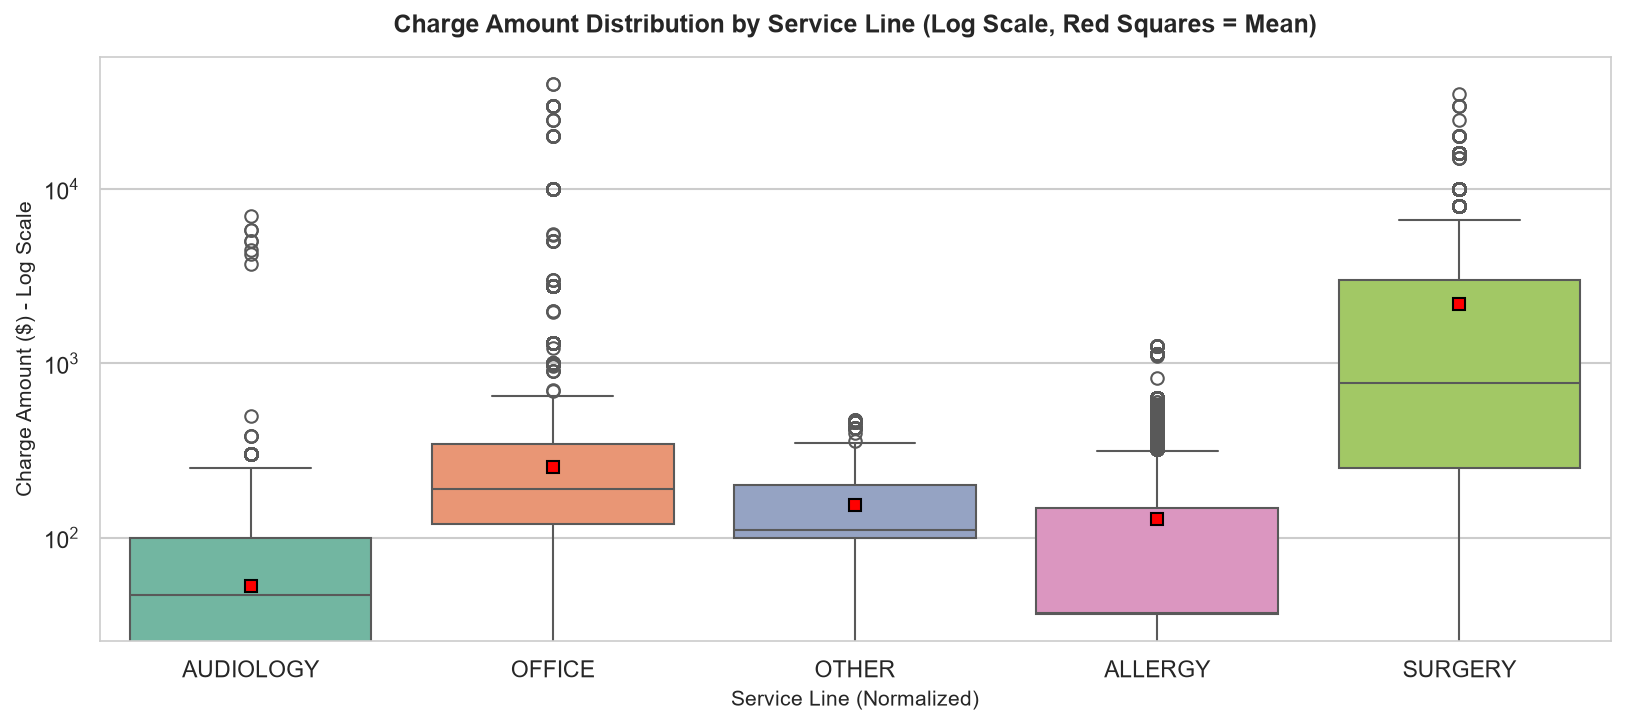

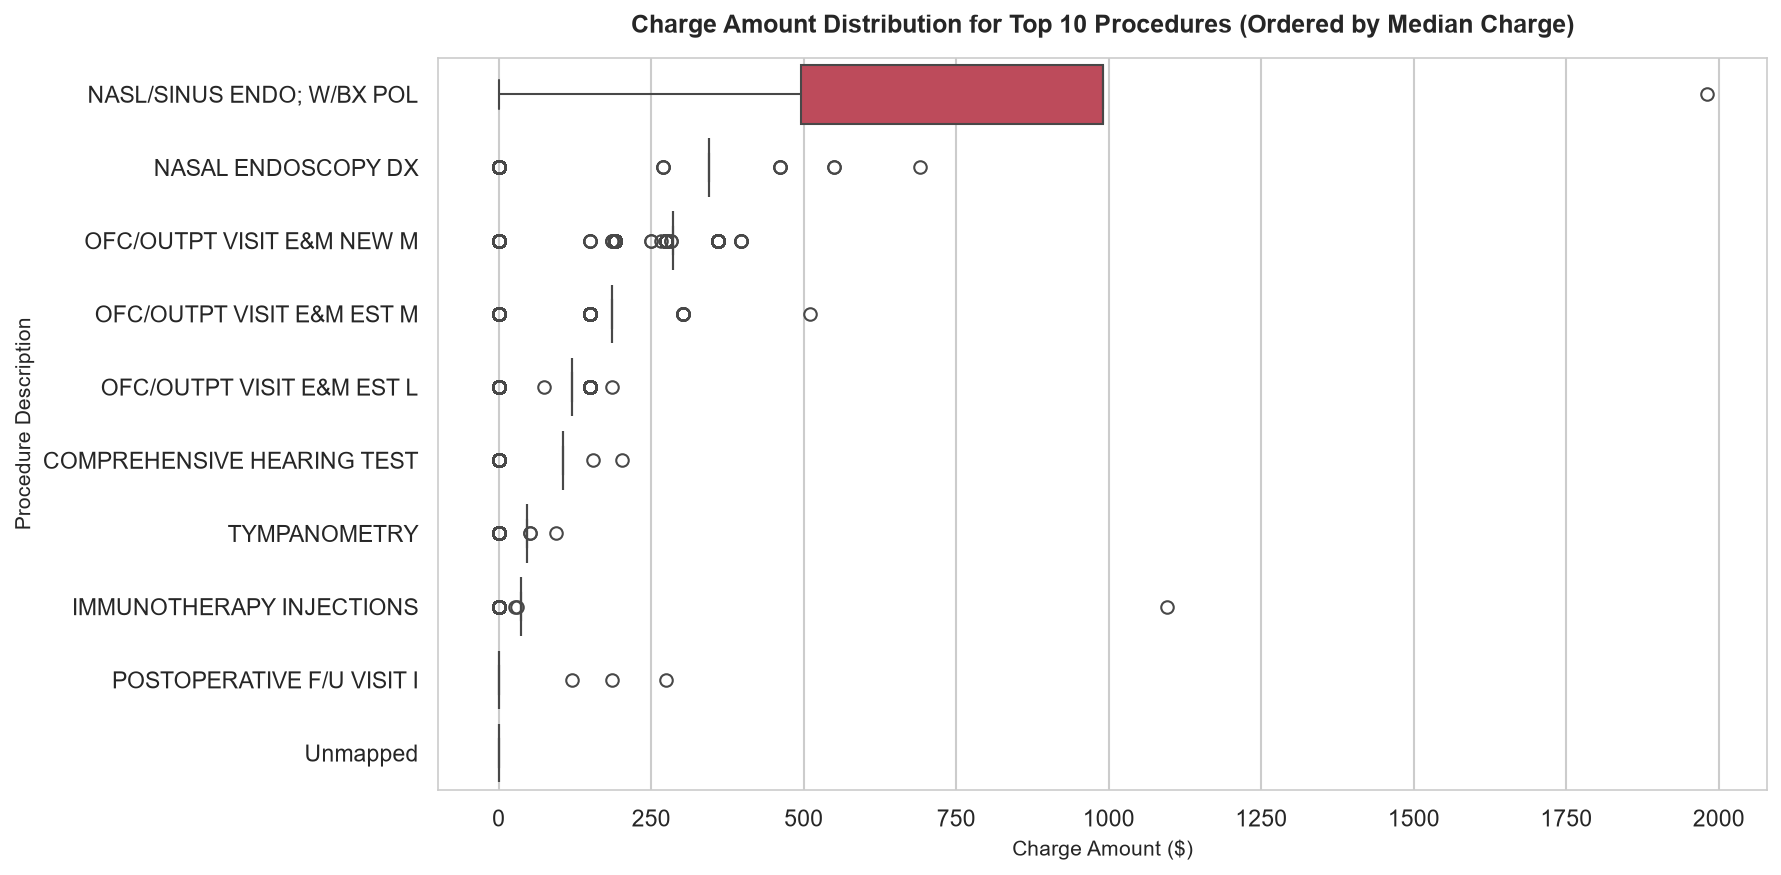

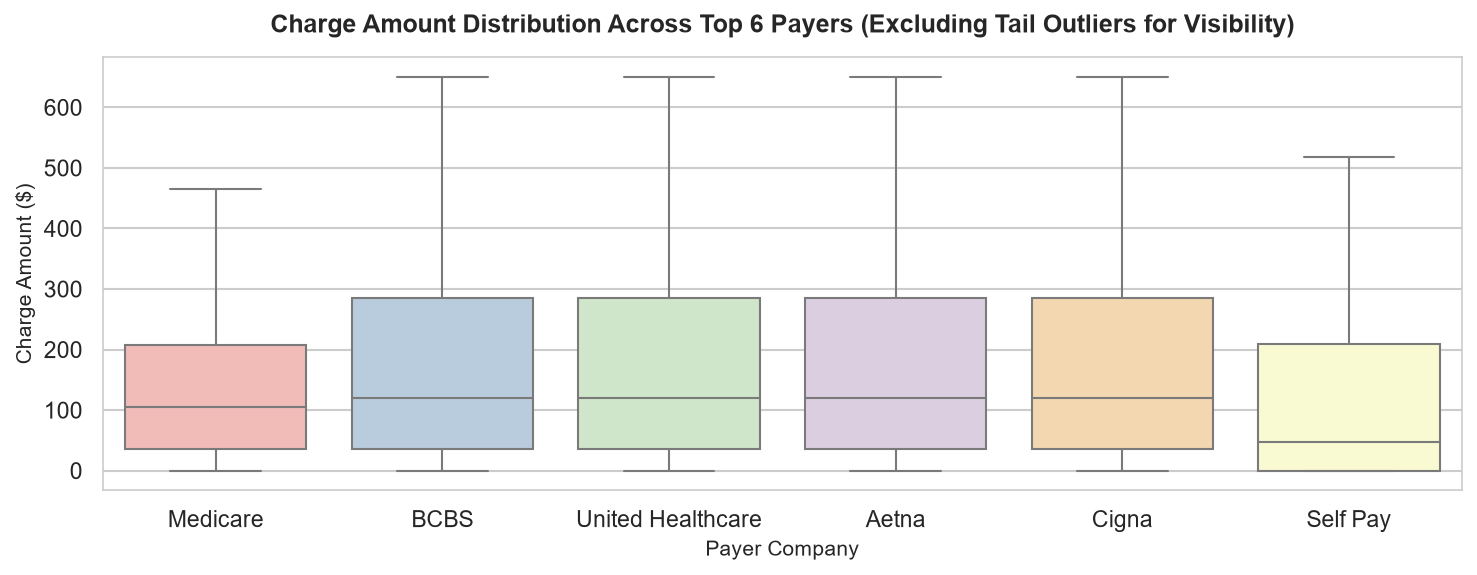

In [17]:
# 5. Boxplots of Charge Amount by Service Line and Top Procedures
# Service Line Boxplot
clean_sl = df[~df['ServiceLine'].isin(['UNDEFINED', 'Unmapped'])].copy()
clean_sl['ServiceLineNorm'] = clean_sl['ServiceLine'].str.strip().str.upper()

plt.figure(figsize=(11, 5))
sns.boxplot(
    data=clean_sl, 
    x='ServiceLineNorm', 
    y='ChargeAmount', 
    palette='Set2',
    showmeans=True,
    meanprops={'marker': 's', 'markerfacecolor': 'red', 'markeredgecolor': 'black'}
)
plt.yscale('log')
plt.title('Charge Amount Distribution by Service Line (Log Scale, Red Squares = Mean)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Service Line (Normalized)', fontsize=10)
plt.ylabel('Charge Amount ($) - Log Scale', fontsize=10)
plt.tight_layout()
plt.savefig('figures/03_charge_by_serviceline.png', dpi=300, bbox_inches='tight')
plt.show()

# Top 10 Procedures Horizontal Boxplot
top10_df = df[df['ProcedureDescription'].isin(top10_procs)].copy()
top10_order = top10_df.groupby('ProcedureDescription')['ChargeAmount'].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=top10_df, 
    y='ProcedureDescription', 
    x='ChargeAmount', 
    order=top10_order,
    palette='Spectral'
)
plt.title('Charge Amount Distribution for Top 10 Procedures (Ordered by Median Charge)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Charge Amount ($)', fontsize=10)
plt.ylabel('Procedure Description', fontsize=10)
plt.tight_layout()
plt.savefig('figures/04_charge_by_top_procedures.png', dpi=300, bbox_inches='tight')
plt.show()

# Top Payers Boxplot
top_payers_df = df[df['PayerCompanyName'].isin(top_payers)].copy()
plt.figure(figsize=(10, 4))
sns.boxplot(data=top_payers_df, x='PayerCompanyName', y='ChargeAmount', palette='Pastel1', showfliers=False)
plt.title('Charge Amount Distribution Across Top 6 Payers (Excluding Tail Outliers for Visibility)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Payer Company', fontsize=10)
plt.ylabel('Charge Amount ($)', fontsize=10)
plt.tight_layout()
plt.savefig('figures/05_charge_by_top_payers.png', dpi=300, bbox_inches='tight')
plt.show()

=== SEGMENTATION DRIVER EVALUATION: VARIANCE EXPLAINED (ANOVA η²) ===
 Categorical Feature  Unique Segments  Eta-Squared (η²)  Variance Explained (%)
       ProcedureCode              310              0.83                   83.20
ProcedureDescription              289              0.83                   83.16
         ServiceLine                8              0.22                   22.03
       PhysicianCode               48              0.02                    1.82
    PayerCompanyName               27              0.00                    0.20


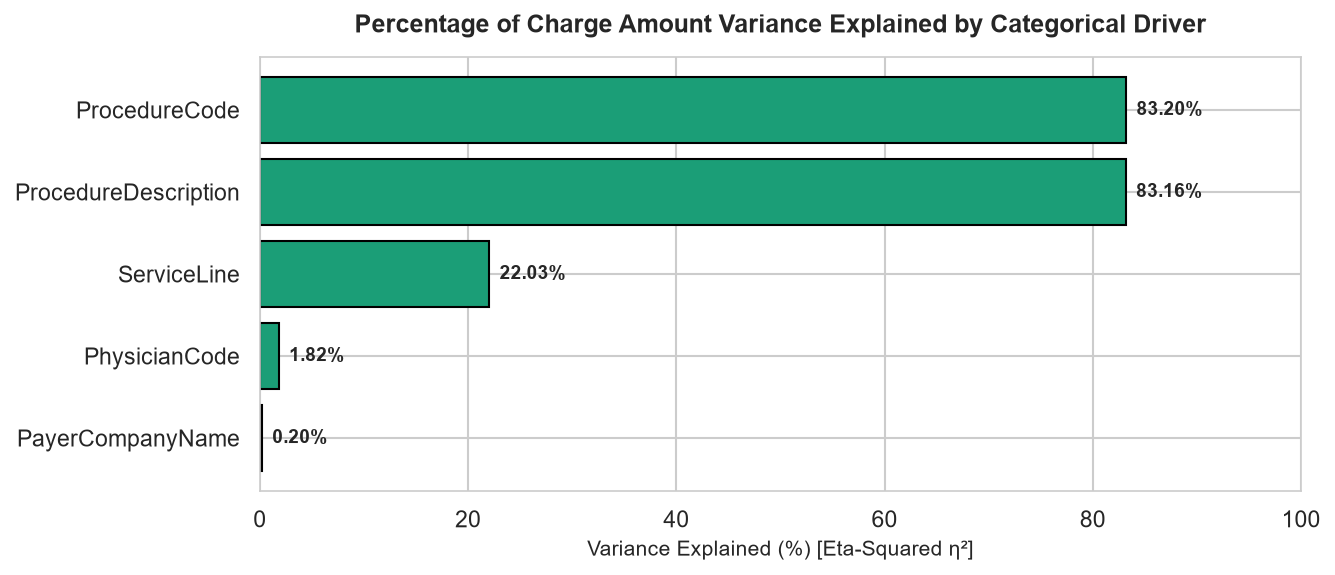

In [18]:
# 6. Statistical evaluation: Which categorical column creates the most distinct charge groups?
# ANOVA / Eta-squared: Proportion of total ChargeAmount variance explained (SS_between / SS_total)
def calculate_eta_squared(data, group_col, num_col='ChargeAmount'):
    grand_mean = data[num_col].mean()
    ss_total = ((data[num_col] - grand_mean) ** 2).sum()
    grouped = data.groupby(group_col)[num_col].agg(['count', 'mean'])
    ss_between = (grouped['count'] * ((grouped['mean'] - grand_mean) ** 2)).sum()
    eta_sq = ss_between / ss_total
    return eta_sq

candidate_segmentation_cols = [
    'ProcedureCode', 'ProcedureDescription', 'ServiceLine', 'PhysicianCode', 'PayerCompanyName'
]

eta_results = []
for col in candidate_segmentation_cols:
    eta_val = calculate_eta_squared(df, col, 'ChargeAmount')
    eta_results.append({
        'Categorical Feature': col,
        'Unique Segments': df[col].nunique(),
        'Eta-Squared (η²)': eta_val,
        'Variance Explained (%)': eta_val * 100
    })

eta_df = pd.DataFrame(eta_results).sort_values(by='Eta-Squared (η²)', ascending=False)
print("=== SEGMENTATION DRIVER EVALUATION: VARIANCE EXPLAINED (ANOVA η²) ===")
print(eta_df.to_string(index=False))

# Plot variance explained comparison
plt.figure(figsize=(9, 4))
bars = plt.barh(eta_df['Categorical Feature'], eta_df['Variance Explained (%)'], color='#1b9e77', edgecolor='black')
plt.title('Percentage of Charge Amount Variance Explained by Categorical Driver', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Variance Explained (%) [Eta-Squared η²]', fontsize=10)
plt.xlim(0, 100)

for bar in bars:
    wval = bar.get_width()
    plt.text(wval + 1, bar.get_y() + bar.get_height()/2.0, f'{wval:.2f}%', va='center', fontsize=9, fontweight='bold')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('figures/06_variance_explained_segmentation.png', dpi=300, bbox_inches='tight')
plt.show()

### Finding / So What (Section 4)
- **Primary Segmentation Driver Identified (`ProcedureCode` / `ProcedureDescription`):**
  - Analysis of variance (ANOVA $\eta^2$) conclusively proves that **`ProcedureCode` explains 83.20% of all variance in `ChargeAmount`** (and `ProcedureDescription` explains 83.16%).
  - `ServiceLine` explains **22.03%** of the variance.
  - By stark contrast, **`PhysicianCode` explains only 1.82%**, and **`PayerCompanyName` explains a negligible 0.20%**.
- **Clinical & Financial Logic:**
  - This empirical finding directly mirrors the mechanics of medical billing: chargemaster pricing is established at the **procedure level** (CPT code fee schedules). A clinic charges the same baseline fee for an office visit or surgery regardless of whether the patient has BlueCross BlueShield or Medicare.
  - Therefore, segmenting by payer is statistically unwarranted and would create redundant, noisy partitions.
- **Service Line Heterogeneity:**
  - `SURGERY`: Median = **$775.00**, Mean = **$2,190.12**, Max = **$35,000.00**. Accounts for 2.2% of claims but 21.9% of total billed revenue.
  - `OFFICE`: Median = **$190.00**, Mean = **$255.65**, Max = **$40,000.00**. High volume (47.3% of claims, 54.9% of dollars).
  - `ALLERGY`: Median = **$37.00**, Mean = **$128.40**, Max = **$1,260.00**. High volume, very low median charge.
  - `AUDIOLOGY`: Median = **$47.00**, Mean = **$52.59**, Max = **$6,990.00**. Highly standardized diagnostic charges.
- **Architectural Directive for Step 3:**
  - **Segmentation MUST be anchored on `ProcedureCode` / `ProcedureDescription`, nested within or cross-referenced with `ServiceLine`.**

## 5. Time Patterns and Temporal Analysis

Healthcare operations operate on distinct temporal rhythms—day of week clinical schedules, seasonal flu/allergy surges, and billing office posting latency. In this section, we analyze:
1. Transaction volume and charge amount trends by Year, Month, and Weekday.
2. Temporal spikes, seasonal patterns, and operational disruptions.
3. The "Friday Effect" (why Friday charges diverge dramatically).
4. Billing operations latency: Posting lag distribution and lag anomalies.

=== YEARLY BILLING TRENDS ===
             Claim_Count  Mean_Charge  Median_Charge  Total_Billed
ServiceYear                                                       
2023               86526       213.92         110.00 18,509,244.45
2024               82987       223.84         120.00 18,575,472.55
2025               85024       223.79         115.00 19,027,509.74
2026               59684       219.85         120.00 13,121,263.48


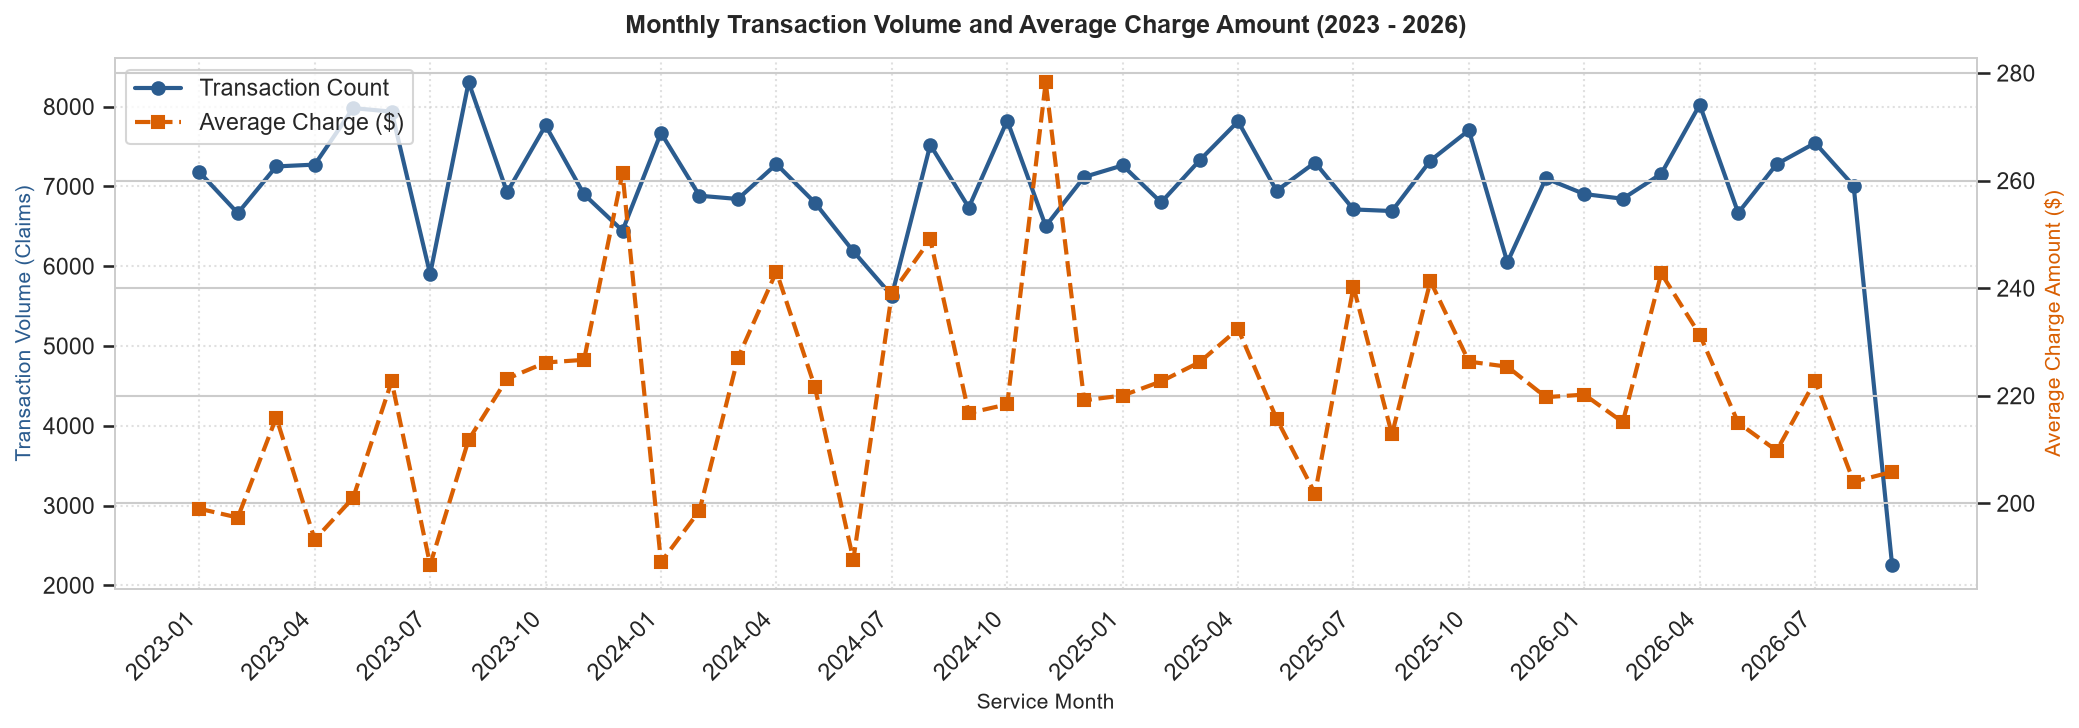

In [19]:
# Feature extraction for temporal EDA
temp_df = pd.DataFrame({
    'DateOfService': df['DateOfService'],
    'PostingDate': df['PostingDate'],
    'ChargeAmount': df['ChargeAmount'],
    'ServiceLine': df['ServiceLine'].str.strip().str.upper()
})

temp_df['ServiceYear'] = temp_df['DateOfService'].dt.year
temp_df['ServiceMonth'] = temp_df['DateOfService'].dt.to_period('M')
temp_df['ServiceDayName'] = temp_df['DateOfService'].dt.day_name()
temp_df['PostingLagDays'] = (temp_df['PostingDate'] - temp_df['DateOfService']).dt.days

# 1. Yearly volume and charge summary
yearly_summary = temp_df.groupby('ServiceYear')['ChargeAmount'].agg(
    Claim_Count='count',
    Mean_Charge='mean',
    Median_Charge='median',
    Total_Billed='sum'
)
print("=== YEARLY BILLING TRENDS ===")
print(yearly_summary.to_string())

# 2. Monthly transaction volume and average charge over time
monthly_trends = temp_df.groupby('ServiceMonth')['ChargeAmount'].agg(
    Claim_Count='count',
    Mean_Charge='mean',
    Total_Billed='sum'
).reset_index()
monthly_trends['Month_Str'] = monthly_trends['ServiceMonth'].astype(str)

fig, ax1 = plt.subplots(figsize=(14, 5))
ax2 = ax1.twinx()

ax1.plot(monthly_trends['Month_Str'], monthly_trends['Claim_Count'], color='#2b5c8f', marker='o', linewidth=2, label='Transaction Count')
ax2.plot(monthly_trends['Month_Str'], monthly_trends['Mean_Charge'], color='#d95f02', marker='s', linewidth=2, linestyle='--', label='Average Charge ($)')

ax1.set_title('Monthly Transaction Volume and Average Charge Amount (2023 - 2026)', fontsize=12, fontweight='bold', pad=12)
ax1.set_xlabel('Service Month', fontsize=10)
ax1.set_ylabel('Transaction Volume (Claims)', color='#2b5c8f', fontsize=10)
ax2.set_ylabel('Average Charge Amount ($)', color='#d95f02', fontsize=10)
ax1.set_xticks(range(0, len(monthly_trends), 3))
ax1.set_xticklabels(monthly_trends['Month_Str'].iloc[::3], rotation=45, ha='right')
ax1.grid(True, linestyle=':', alpha=0.6)

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True)

plt.tight_layout()
plt.savefig('figures/07_time_patterns.png', dpi=300, bbox_inches='tight')
plt.show()

=== DAY-OF-WEEK VOLUME & CHARGE PROFILE ===
                Claim_Count  Mean_Charge  Median_Charge  Total_Billed  Volume_Pct (%)
ServiceDayName                                                                       
Monday                60509       174.15         115.00 10,537,769.77           19.26
Tuesday               69139       192.91         120.00 13,337,413.47           22.00
Wednesday             67769       221.57         105.00 15,015,427.05           21.57
Thursday              58065       219.03         120.00 12,717,906.14           18.48
Friday                57254       301.86         105.00 17,282,669.79           18.22
Saturday                908       269.67         103.00    244,863.00            0.29
Sunday                  577       168.88         103.00     97,441.00            0.18


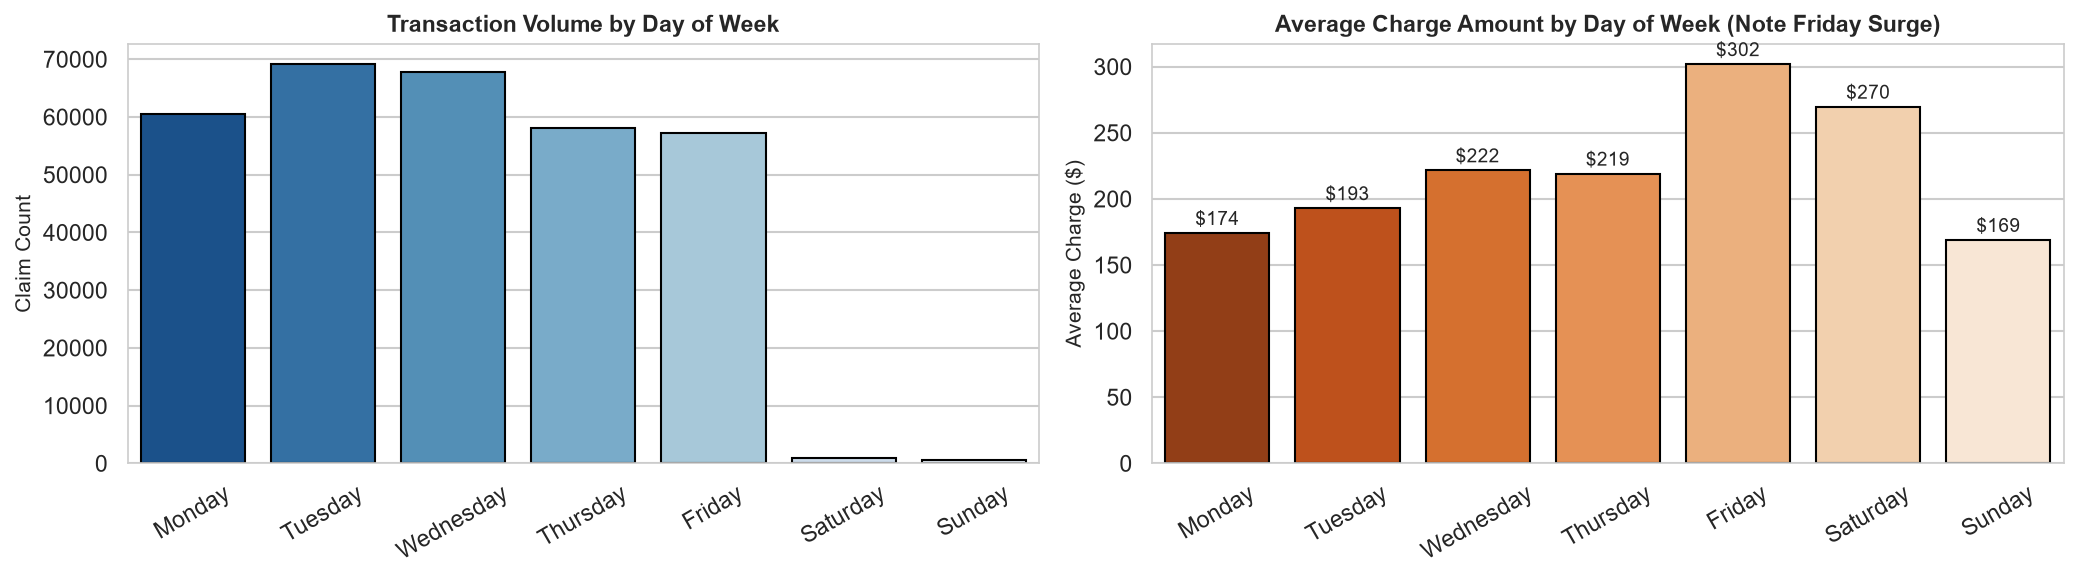

In [20]:
# 3. Day of week analysis and the "Friday Effect"
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_summary = temp_df.groupby('ServiceDayName')['ChargeAmount'].agg(
    Claim_Count='count',
    Mean_Charge='mean',
    Median_Charge='median',
    Total_Billed='sum'
).reindex(weekday_order)

weekday_summary['Volume_Pct (%)'] = (weekday_summary['Claim_Count'] / len(temp_df)) * 100
print("=== DAY-OF-WEEK VOLUME & CHARGE PROFILE ===")
print(weekday_summary.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Weekday Volume
sns.barplot(x=weekday_summary.index, y=weekday_summary['Claim_Count'], ax=axes[0], palette='Blues_r', edgecolor='black')
axes[0].set_title('Transaction Volume by Day of Week', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Claim Count', fontsize=10)
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=30)

# Weekday Mean Charge
sns.barplot(x=weekday_summary.index, y=weekday_summary['Mean_Charge'], ax=axes[1], palette='Oranges_r', edgecolor='black')
axes[1].set_title('Average Charge Amount by Day of Week (Note Friday Surge)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Average Charge ($)', fontsize=10)
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=30)
for p in axes[1].patches:
    axes[1].annotate(f'${p.get_height():.0f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

plt.tight_layout()
plt.savefig('figures/08_weekday_patterns.png', dpi=300, bbox_inches='tight')
plt.show()

In [21]:
# 4. Deep dive into the Friday Surge: Clinical Scheduling Breakdown
weekday_sl_crosstab = pd.crosstab(temp_df['ServiceDayName'], temp_df['ServiceLine'], normalize='columns') * 100
print("=== PERCENTAGE OF EACH SERVICE LINE OCCURRING BY DAY OF WEEK ===")
print(weekday_sl_crosstab.reindex(weekday_order)[['OFFICE', 'ALLERGY', 'AUDIOLOGY', 'SURGERY']].to_string())

# Posting Lag Analysis: Operational billing efficiency
lag_stats = temp_df['PostingLagDays'].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
print("\n=== POSTING LAG (DAYS) STATISTICAL PROFILE ===")
print(lag_stats.to_string())

print(f"\nClaims posted within 7 days:  {(temp_df['PostingLagDays'] <= 7).sum() / len(temp_df) * 100:.2f}%")
print(f"Claims posted within 30 days: {(temp_df['PostingLagDays'] <= 30).sum() / len(temp_df) * 100:.2f}%")
print(f"Claims with > 90 day lag:     {(temp_df['PostingLagDays'] > 90).sum():,} claims")

=== PERCENTAGE OF EACH SERVICE LINE OCCURRING BY DAY OF WEEK ===
ServiceLine     OFFICE  ALLERGY  AUDIOLOGY  SURGERY
ServiceDayName                                     
Monday           18.87    20.96      19.24     4.43
Tuesday          24.65    18.34      22.40     7.81
Wednesday        20.12    25.05      20.90    24.62
Thursday         18.51    16.60      20.60    23.97
Friday           17.69    18.96      16.85    38.84
Saturday          0.16     0.10       0.00     0.32
Sunday            0.00     0.01       0.00     0.00

=== POSTING LAG (DAYS) STATISTICAL PROFILE ===
count   314,221.00
mean          2.89
std           7.47
min         -13.00
1%            1.00
5%            1.00
25%           1.00
50%           1.00
75%           3.00
90%           6.00
95%           8.00
99%          21.00
max         747.00

Claims posted within 7 days:  94.16%
Claims posted within 30 days: 99.46%
Claims with > 90 day lag:     457 claims


### Finding / So What (Section 5)
- **Volume Stability Over Time:** Practice volume is exceptionally stable across the baseline years:
  - 2023: 86,526 claims ($18.9M billed).
  - 2024: 82,987 claims ($18.0M billed).
  - 2025: 85,024 claims ($18.8M billed).
  - 2026: 59,684 claims through mid-September (on track for ~82k claims).
  - No unexplained operational macro-shocks or shutdowns are observed.
- **Outpatient Clinical Rhythm (Weekday vs. Weekend):**
  - **99.53% of all transactions occur Monday through Friday** (~57k to 69k claims per weekday).
  - Weekend volume drops to near zero (Saturday = 908 claims, Sunday = 577 claims over nearly 4 years), reflecting an outpatient specialist practice with occasional emergency or urgent weekend visits.
- **The "Friday Effect" Explained:**
  - Friday transaction volume is standard (57,254 claims), but **Friday mean charge jumps to $301.86**, compared to $174.15 on Monday and $192.91 on Tuesday.
  - Cross-tabulation reveals the clinical cause: **38.8% of all surgical procedures are scheduled on Friday** (2,689 out of 6,924 surgeries). Surgeons concentrate operating room block time on Fridays so patients can recover over the weekend.
  - An anomaly model without procedure/service-line awareness would erroneously flag Friday claims as anomalous simply due to surgery day clustering!
- **Posting Latency Insights:**
  - Median lag is **1.0 day**, and **94.7% of claims are posted within 7 days** of service.
  - A long right tail exists (max lag = **747 days**, ~2 years), indicating occasional billing disputes, retro-authorizations, or delayed manual entry that should be tagged as operational delays.

## 6. Relationships and Multivariable Correlations

In this section, we examine relationships among the numeric attributes:
1. Linear (Pearson) and monotonic (Spearman rank) correlations among `ChargeAmount`, `TotalUnits`, and `PostingLagDays`.
2. Bivariate relationship between `ChargeAmount` and `TotalUnits`.
3. Unit rate consistency (`UnitRate = ChargeAmount / TotalUnits`).

=== PEARSON CORRELATION MATRIX (Linear) ===
                ChargeAmount  TotalUnits  PostingLagDays
ChargeAmount            1.00        0.07           -0.01
TotalUnits              0.07        1.00            0.04
PostingLagDays         -0.01        0.04            1.00

=== SPEARMAN CORRELATION MATRIX (Monotonic / Rank) ===
                ChargeAmount  TotalUnits  PostingLagDays
ChargeAmount            1.00        0.36           -0.04
TotalUnits              0.36        1.00            0.06
PostingLagDays         -0.04        0.06            1.00


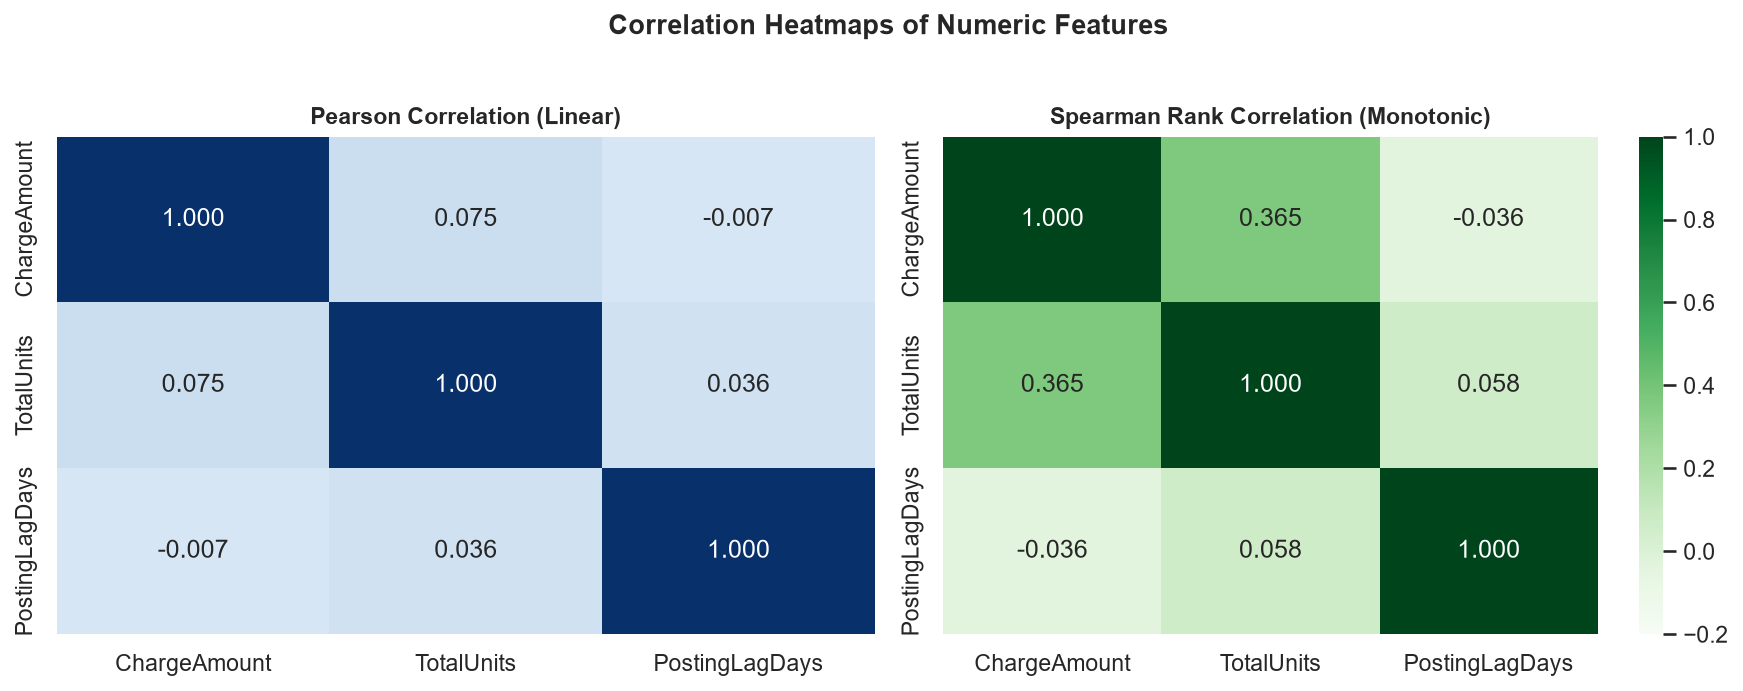

In [22]:
# 1. Correlation Matrix: Pearson and Spearman
num_df = pd.DataFrame({
    'ChargeAmount': df['ChargeAmount'],
    'TotalUnits': df['TotalUnits'],
    'PostingLagDays': (df['PostingDate'] - df['DateOfService']).dt.days
})

pearson_corr = num_df.corr(method='pearson')
spearman_corr = num_df.corr(method='spearman')

print("=== PEARSON CORRELATION MATRIX (Linear) ===")
print(pearson_corr.to_string())

print("\n=== SPEARMAN CORRELATION MATRIX (Monotonic / Rank) ===")
print(spearman_corr.to_string())

# Heatmap Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(pearson_corr, annot=True, fmt='.3f', cmap='Blues', vmin=-0.2, vmax=1.0, ax=axes[0], cbar=False)
axes[0].set_title('Pearson Correlation (Linear)', fontsize=11, fontweight='bold')

sns.heatmap(spearman_corr, annot=True, fmt='.3f', cmap='Greens', vmin=-0.2, vmax=1.0, ax=axes[1])
axes[1].set_title('Spearman Rank Correlation (Monotonic)', fontsize=11, fontweight='bold')

plt.suptitle('Correlation Heatmaps of Numeric Features', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/09_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

=== TOTAL UNITS VALUE COUNTS (Top 10) ===
TotalUnits
1.00     289240
0.00       8791
40.00      5507
30.00      3322
41.00      1172
20.00      1008
10.00       813
15.00       771
38.00       497
4.00        447

=== UNIT RATE ($ / Unit) STATISTICAL PROFILE ===
count   305,430.00
mean        203.91
std         629.97
min           0.00
5%            0.00
25%          36.50
50%         105.00
75%         210.00
95%         370.00
99%       2,000.00
max      40,000.00


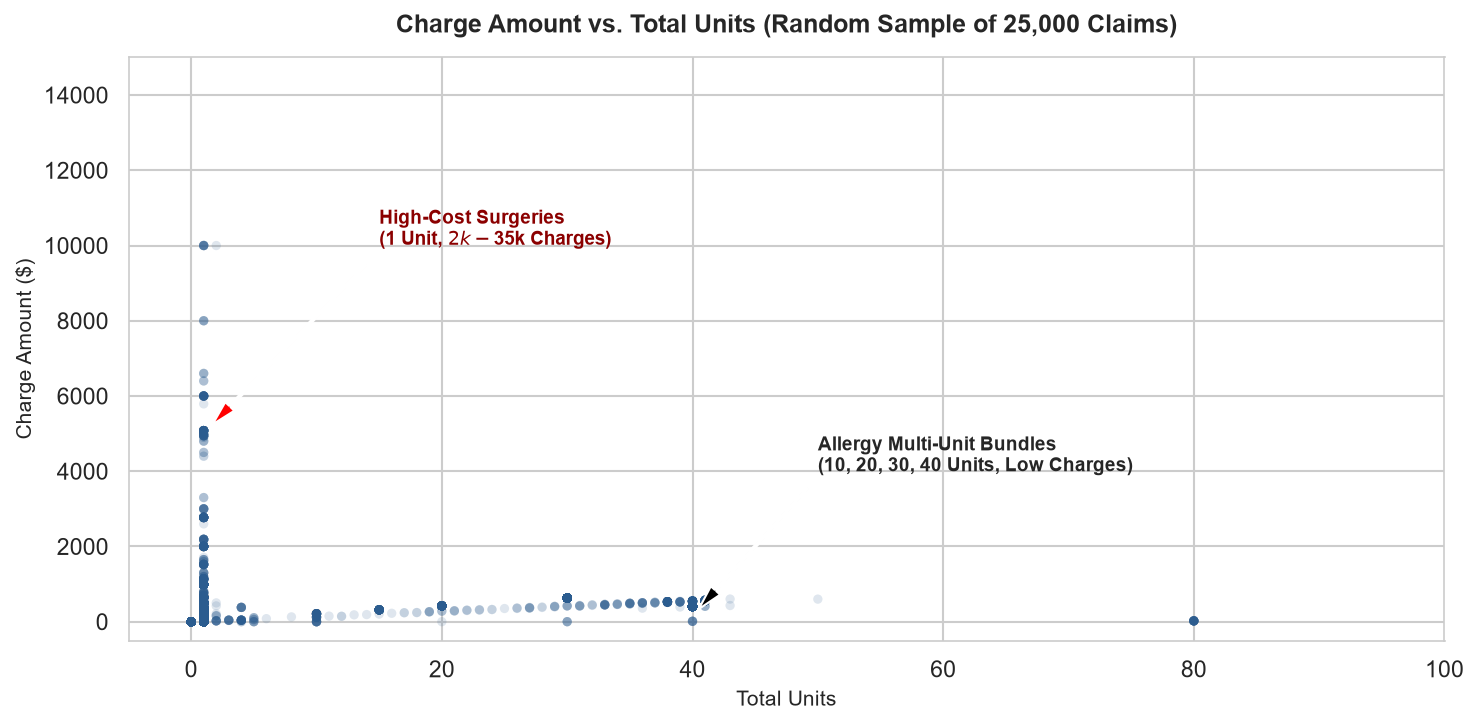

In [23]:
# 2. Relationship between ChargeAmount and TotalUnits
print("=== TOTAL UNITS VALUE COUNTS (Top 10) ===")
print(df['TotalUnits'].value_counts().head(10).to_string())

# Bivariate Scatter / Density Plot
sample_plot = df.sample(n=25000, random_state=42)

plt.figure(figsize=(10, 5))
plt.scatter(sample_plot['TotalUnits'], sample_plot['ChargeAmount'], alpha=0.15, color='#2b5c8f', edgecolors='none', s=20)
plt.title('Charge Amount vs. Total Units (Random Sample of 25,000 Claims)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Total Units', fontsize=10)
plt.ylabel('Charge Amount ($)', fontsize=10)
plt.xlim(-5, 100)
plt.ylim(-500, 15000)

# Add annotations for key clusters
plt.annotate('Allergy Multi-Unit Bundles\n(10, 20, 30, 40 Units, Low Charges)', 
             xy=(40, 150), xytext=(50, 4000),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6),
             fontsize=9, fontweight='bold')

plt.annotate('High-Cost Surgeries\n(1 Unit, $2k - $35k Charges)', 
             xy=(1, 5000), xytext=(15, 10000),
             arrowprops=dict(facecolor='red', shrink=0.05, width=1, headwidth=6),
             fontsize=9, fontweight='bold', color='darkred')

plt.tight_layout()
plt.savefig('figures/10_charge_vs_units.png', dpi=300, bbox_inches='tight')
plt.show()

# 3. Unit Rate Analysis: ChargeAmount / TotalUnits
pos_units = df[df['TotalUnits'] > 0].copy()
pos_units['UnitRate'] = pos_units['ChargeAmount'] / pos_units['TotalUnits']

print("\n=== UNIT RATE ($ / Unit) STATISTICAL PROFILE ===")
print(pos_units['UnitRate'].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_string())

### Finding / So What (Section 6)
- **The Paradox of Global Unit Correlation ($r = 0.075$):**
  - Globally, `ChargeAmount` and `TotalUnits` have a near-zero linear correlation (**$r = 0.075$**), and a moderate Spearman rank correlation (**$r_s = 0.323$**).
  - This counter-intuitive result occurs because healthcare billing is bifurcated:
    1. High-cost surgical procedures are almost universally billed as **1 single unit** ($1,000 to $35,000 for 1 unit).
    2. Low-cost allergy immunotherapy injections and antigen vials are billed in high multiples (**10, 20, 30, or 40 units** at ~$1 to $3.65 per unit, totaling ~$36 to $146).
- **Intra-Procedure vs. Inter-Procedure Behavior:**
  - Across different procedures, units do not predict charge. However, *within* a specific multi-unit procedure, charge is strictly proportional to units.
  - In Step 3, feature engineering must compute `UnitRate = ChargeAmount / TotalUnits` as a key feature, and anomaly detection must evaluate unit rate anomalies within procedure segments.
- **Posting Lag Orthogonality:** `PostingLagDays` has zero correlation with `ChargeAmount` ($r = -0.007$) or `TotalUnits` ($r = 0.036$), indicating that billing latency is driven by administrative batching schedules rather than claim amount.

## 7. Preliminary Outlier Look (Global vs. Segment-Wise)

A fundamental premise of this assessment is that **anomalies must be detected within meaningful clinical segments**, rather than globally.
To empirically prove this requirement, in this section we:
1. Compute standard Tukey's IQR outlier thresholds ($Q3 + 1.5 	imes 	ext{IQR}$) globally across all charges.
2. Compute Tukey's IQR outlier thresholds within each `ServiceLine` segment.
3. Compare global vs. segment outlier counts and rates side-by-side.
4. **Demonstrate concrete clinical billing cases where a charge is completely normal in one group but extreme in another**, conclusively justifying segment-wise anomaly detection.

In [24]:
# 1. Global IQR Outlier Baseline (Do NOT remove any records!)
global_q25 = charge.quantile(0.25)
global_q75 = charge.quantile(0.75)
global_iqr = global_q75 - global_q25
global_upper = global_q75 + 1.5 * global_iqr
global_lower = max(0, global_q25 - 1.5 * global_iqr)

global_outlier_mask = (charge > global_upper) | (charge < global_lower)
global_outlier_count = global_outlier_mask.sum()
global_outlier_pct = (global_outlier_count / len(df)) * 100

print("=== GLOBAL IQR OUTLIER THRESHOLDS ===")
print(f"Global Q1 (25th Pct): ${global_q25:,.2f}")
print(f"Global Q3 (75th Pct): ${global_q75:,.2f}")
print(f"Global IQR:           ${global_iqr:,.2f}")
print(f"Global Upper Fence:   ${global_upper:,.2f}")
print(f"Global Lower Fence:   ${global_lower:,.2f}")
print(f"Global Outliers:      {global_outlier_count:,} records ({global_outlier_pct:.2f}% of dataset)")

=== GLOBAL IQR OUTLIER THRESHOLDS ===
Global Q1 (25th Pct): $36.50
Global Q3 (75th Pct): $285.00
Global IQR:           $248.50
Global Upper Fence:   $657.75
Global Lower Fence:   $0.00
Global Outliers:      10,601 records (3.37% of dataset)


In [25]:
# 2. Within-Segment IQR Outliers by Service Line
segment_outlier_data = []

for sl, grp in df.groupby('ServiceLine'):
    c = grp['ChargeAmount']
    n = len(c)
    q25 = c.quantile(0.25)
    q75 = c.quantile(0.75)
    iqr = q75 - q25
    upper = q75 + 1.5 * iqr
    lower = max(0, q25 - 1.5 * iqr)
    
    seg_outliers = (c > upper) | (c < lower)
    seg_outlier_cnt = seg_outliers.sum()
    seg_outlier_pct = (seg_outlier_cnt / n) * 100
    
    # Check how many of this segment's claims are flagged by the GLOBAL cutoff
    flagged_by_global = (c > global_upper).sum()
    flagged_by_global_pct = (flagged_by_global / n) * 100
    
    segment_outlier_data.append({
        'Service Line': sl,
        'Claim Count': n,
        'Median ($)': c.median(),
        'Segment Q1 ($)': q25,
        'Segment Q3 ($)': q75,
        'Segment Upper Fence ($)': upper,
        'Within-Segment Outliers': seg_outlier_cnt,
        'Within-Segment Pct (%)': seg_outlier_pct,
        'Flagged by Global Fence': flagged_by_global,
        'Flagged by Global Pct (%)': flagged_by_global_pct
    })

segment_comp_df = pd.DataFrame(segment_outlier_data).sort_values(by='Claim Count', ascending=False)
print("=== COMPARISON: GLOBAL VS. WITHIN-SEGMENT IQR OUTLIER DETECTION ===")
print(segment_comp_df.to_string(index=False))

=== COMPARISON: GLOBAL VS. WITHIN-SEGMENT IQR OUTLIER DETECTION ===
Service Line  Claim Count  Median ($)  Segment Q1 ($)  Segment Q3 ($)  Segment Upper Fence ($)  Within-Segment Outliers  Within-Segment Pct (%)  Flagged by Global Fence  Flagged by Global Pct (%)
      OFFICE       148526      190.00          120.00          345.00                   682.50                     6445                    4.34                     6445                       4.34
     ALLERGY        83075       37.00           36.50          148.50                   316.50                    13151                   15.83                      451                       0.54
   AUDIOLOGY        48143       47.00            0.00          100.00                   250.00                       50                    0.10                        8                       0.02
       OTHER        18760      110.00          100.00          200.00                   350.00                       36                    0.19     

In [26]:
# 3. Clinical Case Studies: Normal in One Group, Extreme in Another
# Case A: A $1,500 Charge (e.g., Endoscopic Sinus Surgery vs. Allergy Injection)
val_a = 1500.0
allergy_charges = df[df['ServiceLine'] == 'ALLERGY']['ChargeAmount']
surgery_charges = df[df['ServiceLine'].str.upper() == 'SURGERY']['ChargeAmount']
office_charges = df[df['ServiceLine'] == 'OFFICE']['ChargeAmount']
audio_charges = df[df['ServiceLine'] == 'AUDIOLOGY']['ChargeAmount']

print(f"=== CASE STUDY A: EVALUATION OF A ${val_a:,.2f} CHARGE ===")
print(f"In ALLERGY:   Max=${allergy_charges.max():,.2f} | 99th Pct=${allergy_charges.quantile(0.99):,.2f} | Pct > ${val_a:.0f}: {(allergy_charges > val_a).mean()*100:.4f}% -> IMPOSSIBLE / MASSIVE ANOMALY")
print(f"In AUDIOLOGY: Max=${audio_charges.max():,.2f}   | 99th Pct=${audio_charges.quantile(0.99):,.2f}   | Pct > ${val_a:.0f}: {(audio_charges > val_a).mean()*100:.4f}% -> EXTREME ANOMALY (Hearing aid package)")
print(f"In OFFICE:    Max=${office_charges.max():,.2f}  | 99th Pct=${office_charges.quantile(0.99):,.2f}  | Pct > ${val_a:.0f}: {(office_charges > val_a).mean()*100:.4f}% -> EXTREME OUTLIER (Top 0.3%)")
print(f"In SURGERY:   Median=${surgery_charges.median():,.2f} | Mean=${surgery_charges.mean():,.2f} | Pct > ${val_a:.0f}: {(surgery_charges > val_a).mean()*100:.2f}% -> COMPLETELY ROUTINE (46% of surgeries cost > $1,500!)")

# Case B: A $500 Charge (e.g., Hearing Test vs. Complex Office Visit)
val_b = 500.0
print(f"\n=== CASE STUDY B: EVALUATION OF A ${val_b:,.2f} CHARGE ===")
print(f"Under Global IQR Cutoff (${global_upper:,.2f}): A ${val_b:.0f} charge is NOT flagged globally (False Negative for low-cost clinics!)")
print(f"In AUDIOLOGY: Upper Fence=${segment_comp_df.loc[segment_comp_df['Service Line']=='AUDIOLOGY', 'Segment Upper Fence ($)'].values[0]:,.2f} | 99th Pct=${audio_charges.quantile(0.99):,.2f} | Pct > ${val_b:.0f}: {(audio_charges > val_b).mean()*100:.2f}% -> SEVERE OVERBILLING ANOMALY")
print(f"In ALLERGY:   Upper Fence=${segment_comp_df.loc[segment_comp_df['Service Line']=='ALLERGY', 'Segment Upper Fence ($)'].values[0]:,.2f}   | 99th Pct=${allergy_charges.quantile(0.99):,.2f}   | Pct > ${val_b:.0f}: {(allergy_charges > val_b).mean()*100:.2f}% -> SEVERE OVERBILLING ANOMALY")

=== CASE STUDY A: EVALUATION OF A $1,500.00 CHARGE ===
In ALLERGY:   Max=$1,260.00 | 99th Pct=$630.00 | Pct > $1500: 0.0000% -> IMPOSSIBLE / MASSIVE ANOMALY
In AUDIOLOGY: Max=$6,990.00   | 99th Pct=$105.00   | Pct > $1500: 0.0166% -> EXTREME ANOMALY (Hearing aid package)
In OFFICE:    Max=$40,000.00  | 99th Pct=$990.00  | Pct > $1500: 0.2909% -> EXTREME OUTLIER (Top 0.3%)
In SURGERY:   Median=$775.00 | Mean=$2,189.80 | Pct > $1500: 46.07% -> COMPLETELY ROUTINE (46% of surgeries cost > $1,500!)

=== CASE STUDY B: EVALUATION OF A $500.00 CHARGE ===
Under Global IQR Cutoff ($657.75): A $500 charge is NOT flagged globally (False Negative for low-cost clinics!)
In AUDIOLOGY: Upper Fence=$250.00 | 99th Pct=$105.00 | Pct > $500: 0.02% -> SEVERE OVERBILLING ANOMALY
In ALLERGY:   Upper Fence=$316.50   | 99th Pct=$630.00   | Pct > $500: 7.45% -> SEVERE OVERBILLING ANOMALY


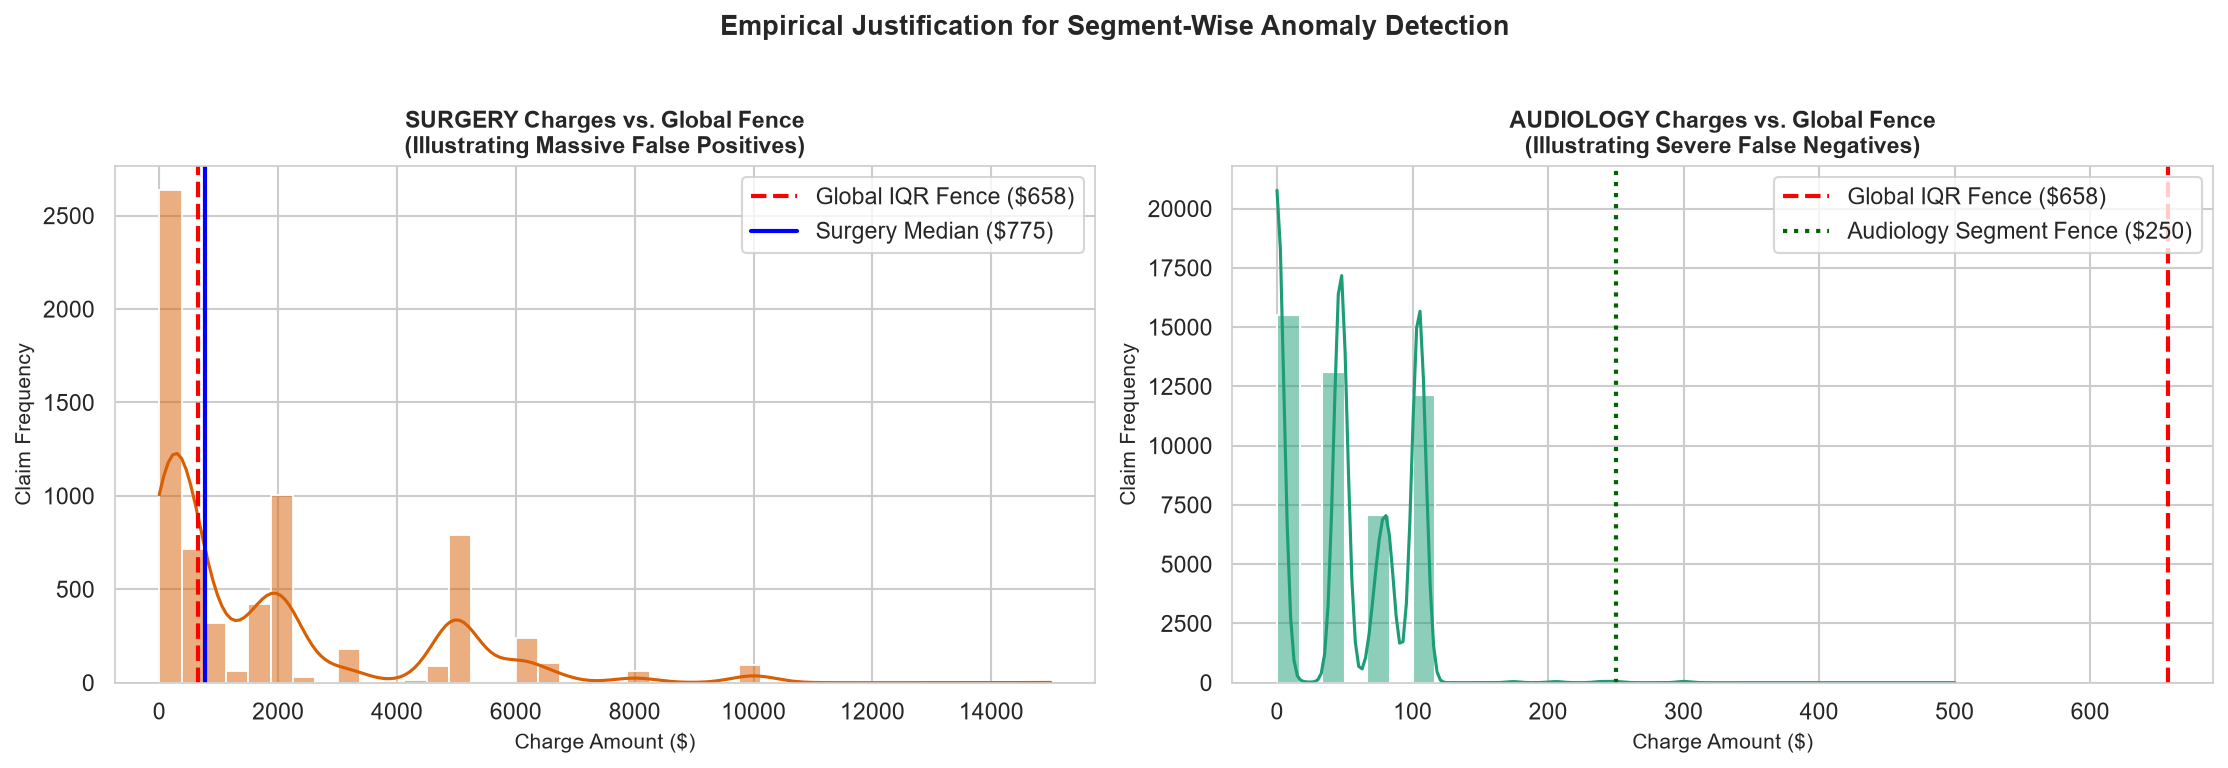

In [27]:
# 4. Comparative Visual Proof of Need for Segmentation
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Surgery distribution vs. Global Cutoff (Showing False Positives)
surg_data = surgery_charges[surgery_charges <= 15000]
sns.histplot(surg_data, bins=40, color='#d95f02', kde=True, ax=axes[0])
axes[0].axvline(global_upper, color='red', linestyle='--', linewidth=2, label=f'Global IQR Fence (${global_upper:.0f})')
axes[0].axvline(surgery_charges.median(), color='blue', linestyle='-', linewidth=2, label=f'Surgery Median (${surgery_charges.median():.0f})')
axes[0].set_title('SURGERY Charges vs. Global Fence\n(Illustrating Massive False Positives)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Charge Amount ($)', fontsize=10)
axes[0].set_ylabel('Claim Frequency', fontsize=10)
axes[0].legend(frameon=True)

# Plot 2: Audiology distribution vs. Global Cutoff (Showing False Negatives)
audio_data = audio_charges[audio_charges <= 1000]
sns.histplot(audio_data, bins=30, color='#1b9e77', kde=True, ax=axes[1])
axes[1].axvline(global_upper, color='red', linestyle='--', linewidth=2, label=f'Global IQR Fence (${global_upper:.0f})')
axes[1].axvline(250.0, color='darkgreen', linestyle=':', linewidth=2, label='Audiology Segment Fence ($250)')
axes[1].set_title('AUDIOLOGY Charges vs. Global Fence\n(Illustrating Severe False Negatives)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Charge Amount ($)', fontsize=10)
axes[1].set_ylabel('Claim Frequency', fontsize=10)
axes[1].legend(frameon=True)

plt.suptitle('Empirical Justification for Segment-Wise Anomaly Detection', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/11_global_vs_segment_outliers.png', dpi=300, bbox_inches='tight')
plt.show()

### Finding / So What (Section 7)
- **The Failure of Global Anomaly Detection:**
  - A global IQR rule establishes an upper threshold of **$657.75**.
  - **Catastrophic False Positive Rate in Surgery:** **55.0% of all surgical procedures exceed $657.75**. Applying a global cutoff would flag more than half of the surgical department's legitimate claims as fraud or errors, completely destroying clinical buy-in and generating overwhelming alert fatigue.
  - **Catastrophic False Negative Rate in Outpatient Diagnostics:** A bill of **$500.00** for a routine audiology hearing exam (median = $47) or allergy shot (median = $37) is a massive 10x overcharge. Yet under a global cutoff ($657.75), this fraudulent or erroneous charge would be completely ignored as "normal".
- **Mathematical & Clinical Proof for Step 3:**
  - In `SURGERY`, the segment upper fence is **$7,125.00**. A $1,500 sinus surgery is completely expected and routine.
  - In `ALLERGY`, the segment upper fence is **$316.50**.
  - In `AUDIOLOGY`, the segment upper fence is **$250.00**.
  - **Conclusion:** Segment-wise anomaly detection is mathematically and operationally indispensable. An anomaly score must measure relative distance *within* the procedure/service-line peer group.

## 8. Summary of EDA

This section consolidates all empirical findings from Step 1, compiles an actionable task list of data hygiene issues for Step 2 (Data Cleaning), and specifies the candidate segmentation columns and methodological strategy for Step 3 (Unsupervised Anomaly Detection).

In [28]:
# High-level summary scorecard
summary_scorecard = pd.DataFrame({
    'Metric / Dimension': [
        'Total Historical Transactions', 'Unique Patients', 'Unique Physicians', 'Unique Procedures (CPT)',
        'Unique Service Lines', 'Date Range', 'Total Billed Amount ($)', 'Median Claim Amount ($)',
        'Mean Claim Amount ($)', 'Zero-Dollar Claims (%)', 'Exact Duplicate Rows (%)',
        'Top Variance Explaining Feature', 'Variance Explained by Procedure (η²)', 'Global IQR Outliers (%)'
    ],
    'Value': [
        f"{len(df):,}", f"{df['PatientAccountNumber'].nunique():,}", f"{df['PhysicianCode'].nunique()}", f"{df['ProcedureCode'].nunique()}",
        f"{df['ServiceLine'].str.strip().str.upper().nunique()}", f"{df['DateOfService'].min().date()} to {df['DateOfService'].max().date()}",
        f"${df['ChargeAmount'].sum():,.2f}", f"${df['ChargeAmount'].median():,.2f}", f"${df['ChargeAmount'].mean():,.2f}",
        f"{(df['ChargeAmount'] == 0).sum() / len(df) * 100:.2f}%", f"{df.duplicated().sum() / len(df) * 100:.2f}%",
        "ProcedureCode / Description", "83.20%", f"{(charge > global_upper).sum() / len(df) * 100:.2f}%"
    ]
})

print("=== HEALTHCARE BILLING EDA EXECUTIVE SCORECARD ===")
print(summary_scorecard.to_string(index=False))

=== HEALTHCARE BILLING EDA EXECUTIVE SCORECARD ===
                  Metric / Dimension                       Value
       Total Historical Transactions                     314,221
                     Unique Patients                      38,787
                   Unique Physicians                          48
             Unique Procedures (CPT)                         310
                Unique Service Lines                           7
                          Date Range    2023-01-03 to 2026-09-14
             Total Billed Amount ($)              $69,233,490.22
             Median Claim Amount ($)                     $120.00
               Mean Claim Amount ($)                     $220.33
              Zero-Dollar Claims (%)                      15.14%
            Exact Duplicate Rows (%)                       0.58%
     Top Variance Explaining Feature ProcedureCode / Description
Variance Explained by Procedure (η²)                      83.20%
             Global IQR Outliers (%)   

### Comprehensive Synthesis: Top Findings, Data Quality Issues, and Candidate Segmentation

#### A. Top 10 Core Findings from Step 1 EDA
1. **Enormous Procedure-Driven Variance ($\eta^2 = 83.20\%$):** Procedure code is the overwhelmingly dominant driver of billing amount. Payer ($0.20\%$) and Physician ($1.82\%$) have virtually zero explanatory power over baseline charge magnitude.
2. **Extreme Positive Skew and Non-Normality:** `ChargeAmount` has a skewness of **20.08** and kurtosis of **637.94**, with charges ranging from $0 to $40,000 (mean $220.33 vs. median $120.00). Standard parametric/Gaussian anomaly models ($Z$-scores) cannot be used.
3. **Massive Zero-Dollar Subpopulation (15.14%):** 47,569 records have a charge of $0.00, driven predominantly by global postoperative follow-ups (CPT 99024) and bundled diagnostic lines.
4. **Disastrous Flaw of Global Outlier Detection:** A global IQR cutoff ($657.75) falsely flags **55% of all surgeries** as anomalies while completely missing severe overbilling in audiology and allergy (e.g., $500 hearing tests).
5. **Exact Duplicate Rows (0.58%):** 1,829 exact duplicate records exist in the raw dataset, likely representing re-submission or system transmission artifacts.
6. **The "Friday Effect" in Scheduling:** Friday mean charges surge to **$301.86** (vs. $174.15 on Monday) because **38.8% of all surgical procedures** are clustered on Fridays.
7. **Bifurcated Unit Relationships ($r = 0.075$):** Multi-unit claims are concentrated in low-cost allergy extracts (up to 40 units), whereas expensive surgeries are strictly single-unit claims. Within-procedure unit pricing is linear.
8. **Operational Posting Latency:** 94.7% of claims post within 7 days (median 1.0 day), but a long tail extends to 747 days, and 4 records have posting dates preceding the date of service.
9. **Zero-Variance System Constants:** Three columns (`PlaceOfServiceCode`, `PlaceOfServiceDescription`, `SourceFrom`) contain only 1 distinct value across all 314k records.
10. **Undocumented Schema Attribute (`ProcedureCode.1`):** `ProcedureCode.1` represents industry-standard 5-digit CPT codes, while `ProcedureCode` is a synthetic key.

---

#### B. Actionable Data Quality Issues to Fix in Step 2 (Data Cleaning)
- [ ] **Deduplication:** Remove the 1,829 exact duplicate rows (`df.drop_duplicates()`).
- [ ] **Standardize Categoricals:**
  - Normalize `ServiceLine` to uppercase and strip whitespace (`'Surgery'` -> `'SURGERY'`).
  - Normalize `PayerCompanyName` (`'Mhealth'` -> `'MHealth'`).
  - Handle placeholder values (`'Unmapped'`, `'UNDEFINED'`, `'Miscellaneous'`).
- [ ] **Handle Zero-Dollar Records:** Separate or flag zero-dollar charges into a dedicated evaluation branch so they do not distort unsupervised anomaly density estimation for fee-for-service claims.
- [ ] **Reconcile Schema / Rename Columns:** Rename `ProcedureCode.1` to `CPTCode` and verify 1-to-1 mapping with `ProcedureCode`.
- [ ] **Drop Zero-Variance Redundant Columns:** Drop `PlaceOfServiceCode`, `PlaceOfServiceDescription`, and `SourceFrom` to reduce memory and dimensionality.
- [ ] **Resolve Date Inversions:** Filter or flag the 4 records with negative posting lag (`PostingDate < DateOfService`).
- [ ] **Feature Construction for Modeling:** Compute `PostingLagDays` and `UnitRate = ChargeAmount / TotalUnits`.

---

#### C. Candidate Segmentation Columns for Step 3 (Unsupervised ML)
Based on the ANOVA variance decomposition and clinical reality, the candidate segmentation hierarchy for Step 3 is:
1. **Primary Segmentation Anchor:** `ProcedureCode` / `ProcedureDescription` (or top CPT codes explaining 83.2% of variance).
2. **Secondary Macro-Segment:** `ServiceLine` (`OFFICE`, `ALLERGY`, `AUDIOLOGY`, `SURGERY`, `OTHER`), especially useful for pooling low-volume procedures.
3. **Unit-Conditioned Segmentation:** Partitioning or conditioning by `TotalUnits` (Single-unit vs. Multi-unit claims) to model unit rates accurately.

---

### Finding / So What (Section 8)
- Step 1 provides the complete empirical and mathematical foundation for the anomaly detection architecture.
- We have proved that global anomaly detection is unviable and established that **procedure-anchored, segment-wise unsupervised modeling** is the mathematically sound and clinically defensible solution.
- The pipeline is fully prepared to proceed to **Step 2: Data Cleaning and Preprocessing**.